# IDW Spatial Interpolation - Lagunazo Mine Waste (pXRF data)

In [ ]:
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy import stats
from scipy.optimize import curve_fit


# 9.1  Station means
def station_means(df, x_col, y_col, var, tol_m=5.0, coords_are_metres=True,
                  agg="mean", verbose=True):
    """Collapse replicate measurements to one value per STATION.

    The original notebooks used ``groupby([Lon, Lat])``, which merges rows only
    when the coordinates are bit-for-bit identical.  Replicates recorded with
    even a 1e-7 degree difference (or re-occupied stations) therefore survived
    as separate records at ~centimetre separation, and leave-one-out
    cross-validation could predict a held-out value from its own siblings.

    This version clusters points within ``tol_m`` metres using a KD-tree and
    single-linkage merging, averages the value, and places the station at the
    centroid of its members.  It also reports the collapse so the notebook can
    state ``n measurements -> m stations`` in the thesis.

    Returns (station_df, report_dict).
    """
    d = df[[x_col, y_col, var]].copy()
    for c in (x_col, y_col, var):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    if d.empty:
        raise ValueError(f"No valid rows for {var}.")

    xy = d[[x_col, y_col]].to_numpy(float)
    if not coords_are_metres:                 
        lat0 = np.deg2rad(np.mean(xy[:, 1]))
        xy = np.column_stack([xy[:, 0] * 111320.0 * np.cos(lat0),
                              xy[:, 1] * 110574.0])

    # single-linkage clustering at tol_m
    tree = cKDTree(xy)
    pairs = tree.query_pairs(r=max(tol_m, 1e-9))
    parent = list(range(len(xy)))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b in pairs:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    labels = np.array([find(i) for i in range(len(xy))])

    d = d.assign(_station=labels)
    agg_fn = "median" if agg == "median" else "mean"
    out = (d.groupby("_station")
             .agg(**{x_col: (x_col, "mean"), y_col: (y_col, "mean"),
                     var: (var, agg_fn), "n_reps": (var, "size"),
                     "rep_sd": (var, "std")})
             .reset_index(drop=True))

    # Guard against single-linkage chaining: a chain of points each just under
    # tol_m apart would otherwise merge into one oversized "station".
    xy_df = pd.DataFrame(xy, columns=["_mx", "_my"]).assign(_station=labels)
    spread = (xy_df.groupby("_station")
                   .apply(lambda gg: float(np.hypot(gg["_mx"].max() - gg["_mx"].min(),
                                                    gg["_my"].max() - gg["_my"].min())))
                   .to_numpy())
    n_chained = int(np.sum(spread > 3.0 * tol_m))

    rep = dict(n_measurements=int(len(d)), n_stations=int(len(out)),
               max_cluster_extent_m=float(np.max(spread)) if spread.size else 0.0,
               n_chained=n_chained,
               max_reps=int(out["n_reps"].max()),
               n_stations_with_reps=int((out["n_reps"] > 1).sum()),
               median_rep_sd=float(out.loc[out["n_reps"] > 1, "rep_sd"].median())
               if (out["n_reps"] > 1).any() else np.nan,
               tol_m=float(tol_m))
    if verbose:
        print(f"Station aggregation ({var}): {rep['n_measurements']} measurements "
              f"-> {rep['n_stations']} stations at a {tol_m:g} m tolerance")
        print(f"  stations with replicates : {rep['n_stations_with_reps']} "
              f"(max {rep['max_reps']} per station)")
        if np.isfinite(rep["median_rep_sd"]):
            print(f"  median within-station SD : {rep['median_rep_sd']:.1f} "
                  f"(a floor on achievable prediction accuracy)")
        print(f"  max cluster extent       : {rep['max_cluster_extent_m']:.1f} m")
        if n_chained:
            print(f"  WARNING: {n_chained} cluster(s) span more than 3x the "
                  f"tolerance - single-linkage\n           chaining may have merged "
                  f"distinct stations. Reduce tol_m or supply an\n           explicit "
                  f"station/sample ID column.")
        if rep["n_measurements"] > rep["n_stations"]:
            print("  NOTE: cross-validation is now performed on station means, so "
                  "leaving out a station removes ALL data from that location.")
    return out.drop(columns=["rep_sd"]), rep



# 9.13  Cell declustering
def declustering_weights(coords, cell_size=None, n_origins=5, target="min_mean"):
    """Cell-declustering weights for judgmental / spatially clustered sampling.

    Weights are normalised to mean 1.0, so a weighted mean is directly
    comparable with the naive mean.  When ``cell_size`` is None the cell size
    that minimises (or maximises) the declustered mean is chosen, which is the
    standard GSLIB procedure: use "min_mean" when high values are clustered
    (the usual case when sampling targets visually conspicuous ground).
    """
    coords = np.asarray(coords, float)
    n = len(coords)
    if n < 3:
        return np.ones(n)

    if cell_size is None:
        d, _ = cKDTree(coords).query(coords, k=min(2, n))
        nn = np.median(d[:, -1])
        extent = float(max(np.ptp(coords[:, 0]), np.ptp(coords[:, 1])))
        candidates = np.unique(np.clip(
            np.array([0.5, 1, 2, 3, 4, 6, 8, 12, 16, 24]) * max(nn, 1.0),
            1.0, extent / 2.0))
    else:
        candidates = np.array([float(cell_size)])

    best = (None, None)
    for cs in candidates:
        means = []
        for o in range(n_origins):
            off = cs * o / max(n_origins, 1)
            ix = np.floor((coords[:, 0] - coords[:, 0].min() + off) / cs).astype(int)
            iy = np.floor((coords[:, 1] - coords[:, 1].min() + off) / cs).astype(int)
            _, inv, cnt = np.unique(np.column_stack([ix, iy]), axis=0,
                                    return_inverse=True, return_counts=True)
            means.append(cnt[inv].astype(float))
        w = 1.0 / np.mean(means, axis=0)
        w *= n / w.sum()
        best = (cs, w) if best[0] is None else best
        if cell_size is not None:
            break
    if cell_size is None:                       # pick the optimising cell size
        scores = []
        for cs in candidates:
            ix = np.floor((coords[:, 0] - coords[:, 0].min()) / cs).astype(int)
            iy = np.floor((coords[:, 1] - coords[:, 1].min()) / cs).astype(int)
            _, inv, cnt = np.unique(np.column_stack([ix, iy]), axis=0,
                                    return_inverse=True, return_counts=True)
            w = 1.0 / cnt[inv].astype(float)
            w *= n / w.sum()
            scores.append((cs, w))
        best = scores[0]
    return best[1]


def declustered_stats(values, weights=None):
    v = np.asarray(values, float)
    w = np.ones_like(v) if weights is None else np.asarray(weights, float)
    w = w / w.sum()
    mean = float(np.sum(w * v))
    var = float(np.sum(w * (v - mean) ** 2))
    order = np.argsort(v)
    cw = np.cumsum(w[order])
    median = float(np.interp(0.5, cw, v[order]))
    return dict(naive_mean=float(v.mean()), declustered_mean=mean,
                declustered_median=median, declustered_sd=float(np.sqrt(var)),
                effect_pct=float(100 * (mean - v.mean()) / v.mean())
                if v.mean() != 0 else np.nan)



# 9.2  Transforms
class Transform:
    """none | log | nscore, with correct back-transformation.

    log     : y = ln(z + c).  Back-transform of a kriged mean uses the
              lognormal correction exp(y_hat + s2/2) - c, where s2 is the
              kriging variance in log space.  This is the standard
              mean-unbiased form; it is sensitive to the variance estimate and
              is reported alongside the median form exp(y_hat) - c.
    nscore  : y = Phi^-1(F(z)).  Back-transform is the inverse anamorphosis,
              which is MEDIAN-unbiased, not mean-unbiased.  For global means and
              above-cut-off tonnages, conditional simulation is the correct
              instrument (comment 9.12); this is stated rather than hidden.
    """

    def __init__(self, kind="none", shift=None):
        self.kind = kind
        self.shift = shift
        self._z = None
        self._y = None

    def fit(self, z):
        z = np.asarray(z, float)
        if self.kind == "log":
            zmin = np.nanmin(z)
            self.shift = (0.0 if zmin > 0 else abs(zmin) + 1e-3) \
                if self.shift is None else self.shift
        elif self.kind == "nscore":
            order = np.argsort(z, kind="mergesort")
            zs = z[order]
            pp = (np.arange(1, len(z) + 1) - 0.5) / len(z)
            self._z, self._y = zs, stats.norm.ppf(pp)
        return self

    def forward(self, z):
        z = np.asarray(z, float)
        if self.kind == "log":
            return np.log(z + self.shift)
        if self.kind == "nscore":
            return np.interp(z, self._z, self._y)
        return z

    def back(self, y, var=None, mean_unbiased=True):
        y = np.asarray(y, float)
        if self.kind == "log":
            if mean_unbiased and var is not None:
                return np.exp(y + np.asarray(var, float) / 2.0) - self.shift
            return np.exp(y) - self.shift
        if self.kind == "nscore":
            return np.interp(y, self._y, self._z)
        return y

    def note(self):
        return {"none": "No transform applied.",
                "log": (f"Natural-log transform, shift c = {self.shift:.4g}. "
                        "Kriged means back-transformed with the lognormal "
                        "correction exp(y+s2/2)-c."),
                "nscore": ("Normal-score transform. Back-transformation is "
                           "median-unbiased; global means and above-cut-off "
                           "tonnages should come from conditional simulation "
                           "(comment 9.12).")}[self.kind]



# 9.3  Variograms
def experimental_variogram(coords, values, n_lags=12, cutoff=None,
                           min_pairs=30, weights=None, verbose=True):
    """Omnidirectional semivariogram with a minimum-pair-count rule.

    The original version returned every bin regardless of support, and the fit
    then included bins carrying 4 and 7 pairs whose gamma values were an order
    of magnitude below the rest.  Bins with fewer than ``min_pairs`` pairs are
    now flagged and excluded from the fit; the sample variance is returned so
    that gamma can be judged against it (a first lag above the sample variance
    indicates outliers or mixed populations, not spatial structure).
    """
    coords = np.asarray(coords, float)
    v = np.asarray(values, float)
    n = len(v)
    if n < 5:
        raise ValueError("At least 5 stations are needed for a variogram.")

    iu = np.triu_indices(n, k=1)
    h = np.hypot(coords[iu[0], 0] - coords[iu[1], 0],
                 coords[iu[0], 1] - coords[iu[1], 1])
    g = 0.5 * (v[iu[0]] - v[iu[1]]) ** 2
    pw = None if weights is None else \
        np.asarray(weights, float)[iu[0]] * np.asarray(weights, float)[iu[1]]

    good = np.isfinite(h) & np.isfinite(g) & (h > 0)
    h, g = h[good], g[good]
    if pw is not None:
        pw = pw[good]
    if cutoff is None:
        cutoff = 0.5 * h.max()
    keep = h <= cutoff
    h, g = h[keep], g[keep]
    if pw is not None:
        pw = pw[keep]

    edges = np.linspace(0.0, cutoff, n_lags + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    gamma = np.full(n_lags, np.nan)
    counts = np.zeros(n_lags, int)
    for i in range(n_lags):
        m = (h >= edges[i]) & ((h < edges[i + 1]) if i < n_lags - 1
                               else (h <= edges[i + 1]))
        if m.any():
            counts[i] = int(m.sum())
            gamma[i] = (np.average(g[m], weights=pw[m]) if pw is not None
                        else float(np.mean(g[m])))
            centers[i] = float(np.mean(h[m]))       # true mean lag distance

    reliable = counts >= min_pairs
    svar = float(np.var(v, ddof=1))
    if verbose:
        dropped = int(np.sum((counts > 0) & ~reliable))
        print(f"Experimental variogram: cutoff {cutoff:.0f} m, {n_lags} lags, "
              f"sample variance {svar:,.0f}")
        if dropped:
            print(f"  {dropped} lag(s) with < {min_pairs} pairs excluded from the "
                  f"fit (unreliable support)")
        first = np.where(reliable)[0]
        if first.size and gamma[first[0]] > svar:
            print("  WARNING: gamma at the first reliable lag exceeds the sample "
                  "variance.\n           This indicates outliers or two mixed "
                  "populations rather than\n           spatial structure - "
                  "transform (9.2) and/or domain the data (9.14).")
    return centers, gamma, counts, reliable, cutoff, svar


def directional_variograms(coords, values, azimuths=(0, 45, 90, 135),
                           tol_deg=22.5, n_lags=8, cutoff=None, min_pairs=20):
    """Screen for anisotropy - the tailings/slag zonation is directional (9.3)."""
    coords = np.asarray(coords, float)
    v = np.asarray(values, float)
    n = len(v)
    iu = np.triu_indices(n, k=1)
    dx = coords[iu[1], 0] - coords[iu[0], 0]
    dy = coords[iu[1], 1] - coords[iu[0], 1]
    h = np.hypot(dx, dy)
    g = 0.5 * (v[iu[0]] - v[iu[1]]) ** 2
    ang = np.degrees(np.arctan2(dx, dy)) % 180.0        # azimuth from north
    if cutoff is None:
        cutoff = 0.5 * h[np.isfinite(h)].max()
    out = {}
    for az in azimuths:
        diff = np.abs((ang - az + 90) % 180 - 90)
        sel = (diff <= tol_deg) & (h > 0) & (h <= cutoff)
        edges = np.linspace(0, cutoff, n_lags + 1)
        cen, gam, cnt = [], [], []
        for i in range(n_lags):
            m = sel & (h >= edges[i]) & (h < edges[i + 1])
            if m.sum() >= min_pairs:
                cen.append(float(np.mean(h[m])))
                gam.append(float(np.mean(g[m])))
                cnt.append(int(m.sum()))
        out[az] = (np.array(cen), np.array(gam), np.array(cnt))
    return out


def anisotropy_report(dirvars, svar):
    """Compare directional variograms at comparable lags; print a verdict."""
    print("\nAnisotropy screening (directional variograms):")
    rows = []
    for az, (cen, gam, cnt) in dirvars.items():
        if cen.size == 0:
            print(f"  {az:3.0f} deg : insufficient pairs")
            continue
        half = gam[cen <= np.median(cen)]
        rows.append((az, float(np.mean(half)) if half.size else np.nan, cen.size))
        print(f"  {az:3.0f} deg : {cen.size} usable lags, "
              f"mean gamma over short lags = {np.mean(half):,.0f}"
              if half.size else f"  {az:3.0f} deg : no short lags")
    if len(rows) >= 2:
        vals = [r[1] for r in rows if np.isfinite(r[1])]
        if vals and min(vals) > 0:
            ratio = max(vals) / min(vals)
            print(f"  directional contrast = {ratio:.2f}x")
            if ratio > 1.5:
                print("  -> anisotropy indicated: an omnidirectional model is not "
                      "defensible.\n     Use an anisotropic model or separate "
                      "domains (comments 9.3, 9.14).")
            else:
                print("  -> no strong anisotropy detected at this sample density; "
                      "an\n     omnidirectional model is acceptable, and this "
                      "screening should be reported.")
    return rows



# IDW
def idw_point(pt, coords, values, tree, p=2.0, k=8, min_k=4, radius=None,
              eps=1e-9, return_info=False):
    """Local IDW with corrected neighbour handling.

    Fixes on the original:
      * ``tree.query`` can return index == n and distance == inf when fewer
        than k points exist; those are now removed before indexing (the original
        would raise IndexError or silently use a wrong sample).
      * The radius/k fallback is explicit and reported, so estimates made
        outside the search radius can be counted rather than hidden.
      * Exact coincidences return the mean of the coincident values.
    """
    n = len(values)
    used_fallback = False
    idx = tree.query_ball_point(pt, r=radius) if (radius and radius > 0) else []
    if len(idx) < min_k:
        used_fallback = True
        kk = int(min(max(min_k, k), n))
        dists, idx = tree.query(pt, k=kk)
        idx = np.atleast_1d(idx)
        dists = np.atleast_1d(dists)
        idx = idx[np.isfinite(dists) & (idx < n)]        # <-- the bug fix
    idx = np.asarray(idx, int)
    if idx.size == 0:
        return (np.nan, dict(n_used=0, fallback=used_fallback)) if return_info else np.nan
    d = np.linalg.norm(coords[idx] - pt, axis=1)
    ok = np.isfinite(d)
    idx, d = idx[ok], d[ok]
    if idx.size > k:
        sel = np.argsort(d)[:k]
        idx, d = idx[sel], d[sel]
    if d.size == 0:
        return (np.nan, dict(n_used=0, fallback=used_fallback)) if return_info else np.nan
    zero = d <= eps
    if np.any(zero):
        est = float(np.mean(values[idx[zero]]))
    else:
        w = 1.0 / np.maximum(d, eps) ** p
        est = float(np.dot(w, values[idx]) / w.sum())
    if return_info:
        return est, dict(n_used=int(idx.size), fallback=used_fallback,
                         d_min=float(d.min()), d_max=float(d.max()))
    return est


def loocv_idw(coords, values, p=2.0, k=8, min_k=4, radius=None):
    """LOOCV on station means (see station_means): removing a station removes
    every measurement made at it."""
    n = len(values)
    if n < 3:
        raise ValueError("LOOCV needs at least three stations.")
    preds = np.full(n, np.nan)
    n_fallback = 0
    for i in range(n):
        keep = np.ones(n, bool)
        keep[i] = False
        tr = cKDTree(coords[keep])
        est, info = idw_point(coords[i], coords[keep], values[keep], tr,
                              p=p, k=min(k, int(keep.sum())),
                              min_k=min(min_k, int(keep.sum())),
                              radius=radius, return_info=True)
        preds[i] = est
        n_fallback += int(info["fallback"])
    return preds, n_fallback


def independent_validation(val_coords, val_values, cal_coords, cal_values,
                           estimator, min_separation_m=10.0, verbose=True):
    """Validate against a hold-out set AFTER removing overlap with calibration.

    The original notebook predicted each validation point from the full
    calibration set.  Where a validation point coincided with a calibration
    point, the exact-hit branch returned that sample's own value, producing an
    R2 of 0.95 against an LOOCV R2 of -0.30.  That is leakage, not validation.
    Here any validation point lying within ``min_separation_m`` of a
    calibration point is excluded and counted.
    """
    val_coords = np.asarray(val_coords, float)
    cal_coords = np.asarray(cal_coords, float)
    d, _ = cKDTree(cal_coords).query(val_coords, k=1)
    keep = d > min_separation_m
    n_drop = int((~keep).sum())
    if verbose:
        print(f"Independent validation: {len(val_coords)} points supplied; "
              f"{n_drop} lie within {min_separation_m:g} m of a calibration "
              f"station and were removed as non-independent.")
        if n_drop:
            print("  (These were the cause of the optimistic validation R2 in the "
                  "previous run.)")
        if keep.sum() == 0:
            print("  WARNING: no genuinely independent validation points remain. "
                  "Report LOOCV only.")
    if keep.sum() == 0:
        return None, None, dict(n_supplied=len(val_coords), n_dropped=n_drop,
                                n_used=0)
    preds = np.array([estimator(pt) for pt in val_coords[keep]])
    return (np.asarray(val_values, float)[keep], preds,
            dict(n_supplied=len(val_coords), n_dropped=n_drop,
                 n_used=int(keep.sum()), min_sep_m=float(d[keep].min())))



# 9.4  Honest metrics
def metrics(y_true, y_pred, label="", kvar=None, sample_range=None):
    """Cross-validation statistics, cleaned up.

    Changes from the original ``calc_metrics``:
      * MAPE removed - meaningless at low grades (it reported 2385 %).
      * R2 and NSE are identical by definition for these inputs; only one is
        reported, with a note, instead of two columns implying two tests.
      * RMSSE added when kriging variances are supplied: it should approach 1.0
        for a correctly scaled variogram model.
      * The estimated range is reported next to the observed range, which is
        what comment 9.4 asks for (interpolators must not be described using
        the input maxima).
    """
    yt = np.asarray(y_true, float)
    yp = np.asarray(y_pred, float)
    ok = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[ok], yp[ok]
    if yt.size == 0:
        return {}
    res = yp - yt
    ss_res = float(np.sum(res ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    rmse = float(np.sqrt(np.mean(res ** 2)))
    slope, intercept = stats.linregress(yt, yp)[:2] if yt.size > 1 else (np.nan,) * 2
    out = dict(
        Label=label, n=int(yt.size),
        RMSE=round(rmse, 3), MAE=round(float(np.mean(np.abs(res))), 3),
        ME_bias=round(float(res.mean()), 3),
        R2_pred=round(float(r2), 4),                 # == Nash-Sutcliffe
        Pearson_r=round(float(np.corrcoef(yt, yp)[0, 1]), 4)
        if yt.std() > 0 and yp.std() > 0 else np.nan,
        Spearman_r=round(float(stats.spearmanr(yt, yp)[0]), 4),
        Rel_RMSE_pct=round(100 * rmse / yt.mean(), 1) if yt.mean() else np.nan,
        Reg_slope=round(float(slope), 4),
        Obs_min=round(float(yt.min()), 1), Obs_max=round(float(yt.max()), 1),
        Est_min=round(float(yp.min()), 1), Est_max=round(float(yp.max()), 1),
        Var_ratio=round(float(np.var(yp) / np.var(yt)), 3) if np.var(yt) > 0 else np.nan,
    )
    if kvar is not None:
        kv = np.asarray(kvar, float)[ok]
        m = kv > 0
        if m.any():
            out["RMSSE"] = round(float(np.sqrt(np.mean((res[m] ** 2) / kv[m]))), 3)
    return out


def interpret_metrics(m):
    """Print the sentences a reviewer will otherwise write for you."""
    print(f"\nInterpretation of {m.get('Label','')}:")
    r2 = m.get("R2_pred", np.nan)
    if np.isfinite(r2):
        if r2 <= 0:
            print(f"  R2 = {r2:.3f} <= 0: the interpolated surface predicts held-out "
                  "stations no\n     better than the sample mean. Report this "
                  "plainly; do not present the map\n     as a predictive model of "
                  "grade.")
        elif r2 < 0.3:
            print(f"  R2 = {r2:.3f}: weak predictive skill, as expected where the "
                  "nugget is high.\n     The comparison identifies which method is "
                  "least poor, not which is accurate.")
        else:
            print(f"  R2 = {r2:.3f}: moderate predictive skill.")
    vr = m.get("Var_ratio", np.nan)
    if np.isfinite(vr) and vr < 0.5:
        print(f"  Variance ratio {vr:.2f}: estimates carry less than half the "
              "variance of the\n     data - strong smoothing. Above-cut-off "
              "tonnages from this surface are\n     upper bounds (comment 9.10); "
              "use conditional simulation for tonnage (9.12).")
    if "RMSSE" in m:
        rs = m["RMSSE"]
        verdict = ("well scaled" if 0.8 <= rs <= 1.25 else
                   "over-optimistic (variances too small)" if rs > 1.25 else
                   "conservative (variances too large)")
        print(f"  RMSSE = {rs:.2f}: kriging variances are {verdict}.")
    if np.isfinite(m.get("Reg_slope", np.nan)) and m["Reg_slope"] < 0.5:
        print(f"  Regression slope {m['Reg_slope']:.2f}: conditional bias - high "
              "grades under-\n     estimated and low grades overestimated, the "
              "classic smoothing signature.")


## 1 · Imports & Configuration


In [182]:
import warnings, time, math, zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
from IPython.display import display
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from scipy import stats
from scipy.ndimage import gaussian_filter
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patheffects as mpe
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import Patch, Rectangle, PathPatch
from matplotlib.lines import Line2D
from matplotlib.path import Path as MPath
try:
    import seaborn as sns
    SNS_OK = True
except ImportError:
    sns = None
    SNS_OK = False
    print("warning: seaborn not found - using matplotlib fallback for heatmaps.")

try:
    import contextily as ctx
    CTX_OK = True
except ImportError:
    CTX_OK = False
    print("warning: contextily not found - basemap disabled.")

try:
    from pyproj import Transformer
    PROJ_OK = True
except ImportError:
    PROJ_OK = False
    print("warning: pyproj not found - UTM reprojection disabled.")

try:
    from shapely.geometry import Polygon as ShapelyPolygon, MultiPoint
    SHAPELY_OK = True
except ImportError:
    SHAPELY_OK = False
    print("warning: shapely not found - install with: pip install shapely")

matplotlib.rcParams.update({
    "figure.dpi":        120,
    "savefig.dpi":       400,
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "font.family":       "DejaVu Sans",
    "font.size":         10,
    "axes.titlesize":    11,
    "axes.labelsize":    10,
    "axes.linewidth":    1.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
})


CSV_DATA       = "Lagunazo_crm_samples_geographic5.csv"      # calibration samples (Lon, Lat, <element>)
CSV_VALIDATION = "lagunazo_validation_dataset2_geographic.csv"  # optional independent hold-out
KMZ_FILE       = "Lagunazo_waste_area.kmz"                   # mine-waste boundary polygon

VAR_NAME       = "Y"          # element column to interpolate
LON_COL        = "Lon"
LAT_COL        = "Lat"
EPSG_UTM       = "EPSG:32629"  # WGS 84 / UTM Zone 29N

# Grid & display
GRID_DENSITY_M = 3.0           # interpolation grid spacing (m)
SMOOTH_SIGMA   = 0.0           # display-only Gaussian sigma in cells; 0 = raw IDW surface
PAD_FRAC       = 0.06          # map padding as a fraction of extent

# IDW parameter search (LOOCV)
P_VALUES       = np.round(np.arange(1.4, 2.61, 0.20), 2)  # distance-decay powers
K_VALUES       = [5, 6, 8, 10, 12]                         # max neighbours
RADIUS_FACTORS = [2.0, 2.5, 3.0, 3.5]                      # search radius = factor x median spacing
MIN_NEIGHBORS  = 4                                          # minimum neighbours per estimate


STATION_TOL_M         = 5.0    # 9.1  replicates within this radius = one station
VALIDATION_MIN_SEP_M  = 10.0   # hold-out points nearer than this are not independent
TRANSFORM             = "none" # 9.2  "none" | "log" | "nscore" (see notes below)

# Classified display
N_GRADE_CLASSES   = 7
N_SUPPORT_CLASSES = 6
GRADE_CMAP     = "turbo"
SUPPORT_CMAP   = "RdYlGn_r"
RESID_CMAP     = "RdBu_r"

print("Configuration loaded.")
print(f"  Element        : {VAR_NAME}")
print(f"  CRS            : {EPSG_UTM} (metres)")
print(f"  Grid spacing   : {GRID_DENSITY_M:g} m   |   display smoothing sigma = {SMOOTH_SIGMA:g} (0 = raw)")
print(f"  Search grid    : {len(P_VALUES)} powers x {len(K_VALUES)} k x {len(RADIUS_FACTORS)} radii")


Configuration loaded.
  Element        : Y
  CRS            : EPSG:32629 (metres)
  Grid spacing   : 3 m   |   display smoothing sigma = 0 (0 = raw)
  Search grid    : 7 powers x 5 k x 4 radii


## 2 · Data Load & Cleaning


In [183]:
# Synthetic fallback generator
def _synth_lagunazo(n=120, seed=7):
    rng = np.random.default_rng(seed)
    cx = np.array([661520, 661600, 661750, 661820, 661680])
    cy = np.array([4165600, 4165720, 4165500, 4165650, 4165560])
    pts = []
    for _ in range(n):
        c = rng.integers(0, len(cx)); a = rng.uniform(0, 2*math.pi); r = rng.exponential(60)
        pts.append([cx[c] + r*math.cos(a), cy[c] + r*math.sin(a)])
    pts = np.array(pts)
    west = pts[:, 0] < 661620
    vals = np.where(west, rng.lognormal(5.5, 0.8, n), rng.lognormal(3.5, 0.7, n))
    vals = np.clip(vals, 2, 650)
    if PROJ_OK:
        tf = Transformer.from_crs("EPSG:32629", "EPSG:4326", always_xy=True)
        lon, lat = tf.transform(pts[:, 0], pts[:, 1])
    else:
        lon = pts[:, 0] / 111320.0 - 8.5; lat = pts[:, 1] / 110574.0 + 37.6
    return pd.DataFrame({LON_COL: lon, LAT_COL: lat, VAR_NAME: vals.round(3)})

# Load the real CSV
if Path(CSV_DATA).exists():
    data = pd.read_csv(CSV_DATA)
    SYNTHETIC = False
    print(f"Loaded '{CSV_DATA}'  ->  {data.shape[0]} rows x {data.shape[1]} cols")
else:
    data = _synth_lagunazo()
    SYNTHETIC = True
    print("=" * 64)
    print("  '" + CSV_DATA + "' NOT found - using SYNTHETIC demonstration data.")
    print("  All figures will be stamped. Numbers are NOT measured values.")
    print("=" * 64)

print(f"  Columns: {list(data.columns)}")
data.head(3)


Loaded 'Lagunazo_crm_samples_geographic5.csv'  ->  274 rows x 22 cols
  Columns: ['Lon', 'Lat', 'As', 'Bi', 'Co', 'Cu', 'Fe', 'Hf', 'Mn', 'Nb', 'Ni', 'Pb', 'Pd', 'Sb', 'Sr', 'Ta', 'Ti', 'V', 'W', 'Y', 'Zn', 'Zr']


,Lon,Lat,As,Bi,Co,Cu,Fe,Hf,Mn,Nb,...,Pd,Sb,Sr,Ta,Ti,V,W,Y,Zn,Zr
0,-7.16783,37.62298,428.1567,,,181.6224,30081.5938,,,34.6758,...,,182.0211,39.8757,,5112.3071,,,,68.8872,310.534
1,-7.16783,37.62298,1248.776,,2307.2395,417.5362,371836.3438,,,,...,,,42.7836,,,,,,267.2824,
2,-7.16783,37.62298,,,,,,,,,...,,,,,,,,,,


In [184]:
# Helper functions
def clean_df(df, var, x_col=LON_COL, y_col=LAT_COL):
    """Coerce to numeric, drop bad rows, and average exact duplicate locations.

    This keeps the original Lon/Lat/<element> workflow, but gives a clear
    message if the chosen column names are not present in the CSV.
    """
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    required = [x_col, y_col, var]
    missing = [c for c in required if c not in df.columns]
    if missing:
        # Try a case-insensitive rescue before failing.
        lower_map = {str(c).strip().lower(): c for c in df.columns}
        resolved = []
        for c in required:
            resolved.append(lower_map.get(str(c).lower(), c))
        if all(c in df.columns for c in resolved):
            x_col, y_col, var = resolved
        else:
            raise KeyError(
                f"Missing required column(s): {missing}. "
                f"Available columns are: {list(df.columns)}. "
                f"Update LON_COL, LAT_COL or VAR_NAME in the configuration cell."
            )
    w = df[[x_col, y_col, var]].copy()
    w[var] = pd.to_numeric(w[var], errors="coerce")
    for c in (x_col, y_col):
        w[c] = pd.to_numeric(w[c], errors="coerce")
    w = w.replace([np.inf, -np.inf], np.nan).dropna(subset=[x_col, y_col, var])
    if w.empty:
        raise ValueError(
            f"No valid rows remain after cleaning {x_col}, {y_col}, and {var}. "
            "Check that the coordinate and element columns are numeric."
        )
    w = w.groupby([x_col, y_col], as_index=False)[var].mean()
    # Restore the expected downstream column names if case-insensitive matching was used.
    rename_back = {x_col: LON_COL, y_col: LAT_COL, var: VAR_NAME}
    w = w.rename(columns=rename_back)
    return w.reset_index(drop=True)

def lonlat_to_utm(lon, lat, epsg=EPSG_UTM):
    """Project lon/lat arrays to UTM metres (single, consistent frame)."""
    if PROJ_OK:
        tf = Transformer.from_crs("EPSG:4326", epsg, always_xy=True)
        x, y = tf.transform(np.asarray(lon, float), np.asarray(lat, float))
        return np.asarray(x, float), np.asarray(y, float)
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    lat0 = float(np.nanmean(lat))
    return ((lon - np.nanmean(lon)) * 111320.0 * np.cos(np.deg2rad(lat0)),
            (lat - lat0) * 110574.0)

def parse_kmz_boundary(kmz_path, epsg_out=EPSG_UTM):
    """Return the outer polygon ring of a KMZ as UTM (x, y); (None, None) if unavailable."""
    if not Path(kmz_path).exists():
        return None, None
    try:
        with zipfile.ZipFile(kmz_path) as z:
            kml_name = next(n for n in z.namelist() if n.endswith(".kml"))
            kml_text = z.read(kml_name).decode("utf-8")
        ns   = {"kml": "http://www.opengis.net/kml/2.2"}
        root = ET.fromstring(kml_text)
        node = root.find(".//kml:coordinates", ns)
        if node is None:
            node = next((e for e in root.iter() if e.tag.endswith("coordinates")), None)
        if node is None or not (node.text and node.text.strip()):
            print("  KMZ parse warning: no coordinate node found.")
            return None, None
        pts = []
        for tok in node.text.strip().split():
            parts = tok.split(",")
            if len(parts) >= 2:
                pts.append((float(parts[0]), float(parts[1])))
        if len(pts) < 3:
            print("  KMZ parse warning: fewer than 3 polygon vertices found.")
            return None, None
        lons = np.array([p[0] for p in pts]); lats = np.array([p[1] for p in pts])
        xs, ys = lonlat_to_utm(lons, lats, epsg=epsg_out)
        if not (xs[0] == xs[-1] and ys[0] == ys[-1]):
            xs = np.append(xs, xs[0]); ys = np.append(ys, ys[0])
        return xs, ys
    except Exception as e:
        print(f"  KMZ parse error: {e}")
        return None, None

def nice_breaks(vmin, vmax, n=7):
    """Rounded equal-interval class breaks spanning [vmin, vmax] (GIS style)."""
    raw = (vmax - vmin) / max(n, 1)
    if raw <= 0:
        return np.linspace(vmin, vmax + 1e-9, n + 1)
    mag  = 10 ** np.floor(np.log10(raw))
    step = max(round(raw / mag) * mag, mag)
    start = np.floor(vmin / step) * step
    edges = [start]
    while edges[-1] < vmax:
        edges.append(edges[-1] + step)
    return np.array(edges)

def write_esri_ascii(path, Z2D, gx, gy, cellsize, nodata=-9999.0):
    """Write a 2-D grid (row 0 = south) as an ESRI ASCII raster for ArcGIS/QGIS/Surfer."""
    arr = np.where(np.isfinite(Z2D), Z2D, nodata)[::-1, :]   # ASCII lists rows north->south
    with open(path, "w") as f:
        f.write(f"ncols {arr.shape[1]}\nnrows {arr.shape[0]}\n")
        f.write(f"xllcorner {gx.min()-cellsize/2:.3f}\nyllcorner {gy.min()-cellsize/2:.3f}\n")
        f.write(f"cellsize {cellsize:.4f}\nNODATA_value {nodata}\n")
        np.savetxt(f, arr, fmt="%.4f")

def synth_banner(fig):
    """Stamp the figure if it was produced from synthetic fallback data."""
    if SYNTHETIC:
        fig.text(0.5, 0.5, "SYNTHETIC DEMONSTRATION DATA — NOT REAL VALUES",
                 ha="center", va="center", rotation=30, fontsize=26, fontweight="bold",
                 color="red", alpha=0.18, zorder=50)


def add_satellite_basemap(ax, xmin, xmax, ymin, ymax, padx, pady,
                          alpha=0.62, zorder=0):
    """Add an Esri WorldImagery satellite basemap below UTM map layers.

    The map extent is set before fetching tiles so the basemap aligns with
    the same UTM frame used by the IDW grids, samples and boundary polygon.
    If contextily/online tiles are unavailable, the original neutral background
    fallback is preserved.
    """
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    if CTX_OK:
        try:
            ctx.add_basemap(
                ax,
                crs=EPSG_UTM,
                source=ctx.providers.Esri.WorldImagery,
                attribution_size=5,
                alpha=alpha,
                zorder=zorder,
                reset_extent=True,
            )
        except Exception as e:
            ax.set_facecolor("#d9e1e8")
            print(f"  Satellite basemap unavailable -> neutral fill ({str(e)[:60]})")
    else:
        ax.set_facecolor("#d9e1e8")

def add_map_furniture(ax, xmin, xmax, ymin, ymax, padx, pady, poly_x, poly_y,
                      vertical_y=True, scale_segs=4, label_axes=True):
    """GIS-style furniture: neatline, graticule, vertical northing labels,
    segmented scale bar and north arrow."""
    for s in ax.spines.values():
        s.set_linewidth(1.4); s.set_color("black"); s.set_zorder(30)
    ax.set_xlim(xmin - padx, xmax + padx); ax.set_ylim(ymin - pady, ymax + pady)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(6))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(direction="in", length=6, width=1.0, labelsize=9,
                   top=True, right=True, colors="black")
    ax.grid(True, ls=":", lw=0.5, color="white", alpha=0.55, zorder=3)
    if vertical_y:                              # northing labels written vertically
        for lab in ax.get_yticklabels():
            lab.set_rotation(90); lab.set_va("center")
            lab.set_ha("center"); lab.set_rotation_mode("anchor")
    if label_axes:
        ax.set_xlabel("", fontsize=10, fontweight="bold")
        ax.set_ylabel("", fontsize=10, fontweight="bold")
    ax.plot(poly_x, poly_y, color="white", lw=3.0, zorder=9, solid_capstyle="round")
    ax.plot(poly_x, poly_y, color="black", lw=1.3, ls="--", zorder=10)
    xext = xmax - xmin + 2 * padx; yext = ymax - ymin + 2 * pady
    raw = (xmax - xmin) * 0.22
    mag = 10 ** int(np.floor(np.log10(raw))) if raw > 0 else 1
    bar = round(raw / mag) * mag; seg = bar / scale_segs
    sx = xmin - padx + 0.045 * xext; sy = ymin - pady + 0.055 * yext; th = 0.012 * yext
    for i in range(scale_segs):
        fc = "black" if i % 2 == 0 else "white"
        ax.add_patch(Rectangle((sx + i * seg, sy), seg, th, fc=fc, ec="black", lw=1.0, zorder=15))
    for i in range(scale_segs + 1):
        ax.text(sx + i * seg, sy - th * 0.5, f"{int(i * seg)}", ha="center", va="top",
                fontsize=7.0, fontweight="bold", zorder=16,
                path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
    ax.text(sx + bar + seg * 0.25, sy + th * 0.5, "m", ha="left", va="center",
            fontsize=8, fontweight="bold", zorder=16,
            path_effects=[mpe.withStroke(linewidth=2, foreground="white")])
    nx = xmax + padx - 0.075 * xext; ny = ymax + pady - 0.105 * yext; al = 0.07 * yext
    ax.annotate("", xy=(nx, ny), xytext=(nx, ny - al), zorder=16,
                arrowprops=dict(arrowstyle="-|>", color="white", lw=4.5, mutation_scale=22))
    ax.annotate("", xy=(nx, ny), xytext=(nx, ny - al), zorder=17,
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.8, mutation_scale=22))
    ax.text(nx, ny + al * 0.18, "N", ha="center", va="bottom", fontsize=15,
            fontweight="bold", zorder=18, color="white",
            path_effects=[mpe.withStroke(linewidth=3.5, foreground="black")])

# Project samples and boundary to UTM 29N
# --- 9.1 station means (replaces exact-coordinate groupby) -------------------
_tmp = clean_df(data, VAR_NAME)
_x0, _y0 = lonlat_to_utm(_tmp[LON_COL].values, _tmp[LAT_COL].values)
_tmp = _tmp.assign(_X=_x0, _Y=_y0)
_st, STATION_REPORT = station_means(_tmp, "_X", "_Y", VAR_NAME,
                                    tol_m=STATION_TOL_M, coords_are_metres=True)
df_work = _st.rename(columns={"_X": "X_utm_", "_Y": "Y_utm_"})
vals_s       = df_work[VAR_NAME].values
xs_utm, ys_utm = df_work["X_utm_"].values, df_work["Y_utm_"].values
coords_utm   = np.column_stack([xs_utm, ys_utm])
N_SAMPLES    = len(vals_s)
if N_SAMPLES < 2:
    raise ValueError("At least two valid sample locations are required for LOOCV and IDW interpolation.")

px_utm, py_utm = parse_kmz_boundary(KMZ_FILE)
if px_utm is not None:
    KMZ_LOADED = True
    print(f"KMZ boundary loaded: {len(px_utm)-1} vertices")
else:
    KMZ_LOADED = False
    if SHAPELY_OK:
        poly = MultiPoint(list(zip(xs_utm, ys_utm))).convex_hull.buffer(60)
        bx, by = poly.exterior.coords.xy
        px_utm, py_utm = np.array(bx), np.array(by)
        print("KMZ not found - using buffered convex hull (60 m).")
    else:
        from scipy.spatial import ConvexHull
        h = ConvexHull(coords_utm)
        px_utm = np.append(xs_utm[h.vertices], xs_utm[h.vertices[0]])
        py_utm = np.append(ys_utm[h.vertices], ys_utm[h.vertices[0]])
        print("KMZ not found - using plain convex hull.")

if SHAPELY_OK:
    boundary_poly = ShapelyPolygon(zip(px_utm, py_utm))
    if not boundary_poly.is_valid:
        boundary_poly = boundary_poly.buffer(0)
    print(f"  Boundary area: {boundary_poly.area/1e4:.2f} ha")
else:
    boundary_poly = None

xmin_u, xmax_u = float(px_utm.min()), float(px_utm.max())
ymin_u, ymax_u = float(py_utm.min()), float(py_utm.max())
pad_x = (xmax_u - xmin_u) * PAD_FRAC; pad_y = (ymax_u - ymin_u) * PAD_FRAC
BND_LABEL = "KMZ waste-area polygon" if KMZ_LOADED else "convex hull (KMZ not found)"

# --- 9.13 declustering -------------------------------------------------------
DECLUS_W = declustering_weights(coords_utm)
DECLUS   = declustered_stats(vals_s, DECLUS_W)
print(f"Declustering: naive mean {DECLUS['naive_mean']:.1f} -> declustered "
      f"{DECLUS['declustered_mean']:.1f} ppm ({DECLUS['effect_pct']:+.1f} %)")
print("  The declustered mean is the one to carry into the volumetric estimate.")

print(f"{N_SAMPLES} stations | {VAR_NAME}: "
      f"min={vals_s.min():.1f}  mean={vals_s.mean():.1f}  max={vals_s.max():.1f} ppm")
print(f"  UTM extent: E {xmin_u:.0f}-{xmax_u:.0f}  N {ymin_u:.0f}-{ymax_u:.0f}")


Station aggregation (Y): 27 measurements -> 26 stations at a 5 m tolerance
  stations with replicates : 1 (max 2 per station)
  median within-station SD : 2.7 (a floor on achievable prediction accuracy)
  max cluster extent       : 2.3 m
  NOTE: cross-validation is now performed on station means, so leaving out a station removes ALL data from that location.
KMZ boundary loaded: 146 vertices
  Boundary area: 16.25 ha
Declustering: naive mean 483.2 -> declustered 460.1 ppm (-4.8 %)
  The declustered mean is the one to carry into the volumetric estimate.
26 stations | Y: min=3.3  mean=483.2  max=3255.6 ppm
  UTM extent: E 661413-661987  N 4165350-4165877


## 3 · IDW Core Functions


In [185]:
# Single-point local IDW and LOOCV are now provided by the corrected core module above (idw_point / loocv_idw / metrics).
calc_metrics = metrics          # keep the old name working
def loocv(coords, values, p=2.0, k=8, min_k=4, radius=None):
    preds, n_fb = loocv_idw(coords, values, p=p, k=k,
                            min_k=min_k, radius=radius)
    return preds
print('IDW core functions bound to the corrected implementations.')

IDW core functions bound to the corrected implementations.


## 4 · Parameter Tuning (LOOCV)


In [186]:
# Median sample spacing
_d, _ = cKDTree(coords_utm).query(coords_utm, k=min(2, N_SAMPLES))
nn = _d[:, -1]; nn = nn[np.isfinite(nn) & (nn > 0)]
if nn.size == 0:
    # Fall back to a small, positive spacing if all samples collapse to one point.
    spacing_m = float(GRID_DENSITY_M)
else:
    spacing_m = float(np.median(nn))
print(f"Median nearest-neighbour spacing: {spacing_m:.1f} m")

# Grid search over power, neighbours and search radius
t0 = time.time(); rows = []
for p in P_VALUES:
    for k in K_VALUES:
        mk = min(MIN_NEIGHBORS, k, N_SAMPLES)
        for rf in RADIUS_FACTORS:
            radius = max(spacing_m * rf, spacing_m * 1.5)
            preds  = loocv(coords_utm, vals_s, p=float(p), k=int(k), min_k=int(mk), radius=radius)
            m = calc_metrics(vals_s, preds, label=f"p={p:.1f} k={k} rf={rf:.1f}")
            if m and m["n"] >= max(6, N_SAMPLES // 3):
                rows.append({**m, "p": float(p), "k_neighbors": int(k),
                             "min_neighbors": int(mk), "radius_factor": float(rf),
                             "search_radius_m": float(radius), "median_spacing_m": spacing_m})

# Selection by cross-validated RMSE (primary) with a small absolute-bias tie-break
tuning_df = pd.DataFrame(rows)
if tuning_df.empty:
    raise ValueError("No valid LOOCV parameter combinations were produced. Check sample count, coordinates, and VAR_NAME.")
# Selection on cross-validated RMSE alone. The previous score mixed RMSE with
# 0.10 x |bias|, which has no statistical justification and let a small bias
# change the chosen power. Bias is reported as a diagnostic instead.
tuning_df = tuning_df.sort_values(["RMSE", "MAE"]).reset_index(drop=True)
tuning_df["Score"] = tuning_df["RMSE"]

print(f"Tuning complete in {time.time()-t0:.1f}s — {len(tuning_df)} parameter sets evaluated\n")
print("Top 10 parameter combinations (ranked by cross-validated RMSE):")
display(tuning_df[["p", "k_neighbors", "radius_factor", "search_radius_m",
                   "RMSE", "MAE", "ME_bias", "R2_pred", "Var_ratio"]].head(10).round(3))


Median nearest-neighbour spacing: 25.0 m
Tuning complete in 0.8s — 140 parameter sets evaluated

Top 10 parameter combinations (ranked by cross-validated RMSE):


,p,k_neighbors,radius_factor,search_radius_m,RMSE,MAE,ME_bias,R2_pred,Var_ratio
0,1.4,12,2.5,62.463,1093.785,785.523,143.095,-0.371,0.355
1,1.4,12,3.5,87.448,1101.247,800.059,145.164,-0.390,0.350
2,1.4,10,2.5,62.463,1101.558,792.687,151.575,-0.390,0.362
3,1.4,10,3.5,87.448,1103.087,802.108,151.233,-0.394,0.352
4,1.4,12,2.0,49.970,1103.267,805.807,135.485,-0.395,0.309
5,1.4,8,3.5,87.448,1108.847,811.412,152.875,-0.409,0.354
6,1.4,8,2.5,62.463,1109.622,806.007,158.038,-0.411,0.368
7,1.4,10,2.0,49.970,1110.422,813.220,148.577,-0.413,0.321
8,1.4,6,2.5,62.463,1112.243,804.387,162.369,-0.418,0.381
9,1.4,12,3.0,74.956,1113.050,791.473,145.430,-0.420,0.402


In [187]:
# Adopt the cross-validation-optimal parameters
best      = tuning_df.iloc[0]
BEST_P    = float(best["p"])
BEST_K    = int(best["k_neighbors"])
BEST_MINK = int(best["min_neighbors"])
BEST_RAD  = float(best["search_radius_m"])
BEST_RF   = float(best["radius_factor"])

print("=" * 55)
print("  CROSS-VALIDATION-OPTIMAL IDW PARAMETERS")
print("=" * 55)
print(f"  Power (p)        : {BEST_P:.2f}")
print(f"  Neighbours (k)   : {BEST_K}   (min {BEST_MINK})")
print(f"  Radius factor    : {BEST_RF:.2f} x spacing")
print(f"  Search radius    : {BEST_RAD:.0f} m")
print(f"  LOOCV RMSE       : {best['RMSE']:.3f} ppm")
print(f"  LOOCV MAE        : {best['MAE']:.3f} ppm")
print(f"  LOOCV R2         : {best['R2_pred']:.3f}")
print(f"  LOOCV slope      : {best['Reg_slope']:.3f}")
print(f"  Relative RMSE    : {best['Rel_RMSE_pct']:.1f} % of mean grade")
print("=" * 55)


  CROSS-VALIDATION-OPTIMAL IDW PARAMETERS
  Power (p)        : 1.40
  Neighbours (k)   : 12   (min 4)
  Radius factor    : 2.50 x spacing
  Search radius    : 62 m
  LOOCV RMSE       : 1093.785 ppm
  LOOCV MAE        : 785.523 ppm
  LOOCV R2         : -0.371
  LOOCV slope      : 0.004
  Relative RMSE    : 226.4 % of mean grade


## 5 · Validation & Performance Metrics


### 5.1 · LOOCV predictions

Leave-one-out predictions at the adopted parameters. Builds `cv_df`; no scoring here.


In [188]:
# 5.1 · LOOCV predictions at the adopted parameters 
# Computation only: this cell builds cv_df and prints nothing but a progress line. All scoring happens in 5.3 so the metrics stand on their own.
preds_cv = loocv(coords_utm, vals_s,
                 p=BEST_P, k=BEST_K, min_k=BEST_MINK, radius=BEST_RAD)

cv_df = df_work.copy()
cv_df["X_utm"] = xs_utm
cv_df["Y_utm"] = ys_utm
cv_df["Predicted_LOOCV"] = preds_cv
cv_df["Residual"]   = preds_cv - vals_s
cv_df["Abs_Error"]  = np.abs(cv_df["Residual"])

_n_ok = int(np.isfinite(preds_cv).sum())
print(f"LOOCV complete: {_n_ok} / {len(preds_cv)} stations predicted "
      f"(p={BEST_P:.2f}, k={BEST_K}, min_k={BEST_MINK}, r={BEST_RAD:.0f} m)")


LOOCV complete: 26 / 26 stations predicted (p=1.40, k=12, min_k=4, r=62 m)


### 5.2 · Independent hold-out validation *(optional)*

Skipped when no validation CSV is present, or when every hold-out point is coincident with a calibration station.


In [189]:
# 5.2 · Independent hold-out validation 
# Runs only when CSV_VALIDATION exists. Hold-out points lying within
# VALIDATION_MIN_SEP_M of a calibration station are dropped, because the
# exact-hit branch of idw_point would hand back the sample's own value.
# Leaves val_metrics / val_df_out as None when no honest hold-out remains.
val_metrics = None
val_df_out  = None

if Path(CSV_VALIDATION).exists():
    val_raw  = clean_df(pd.read_csv(CSV_VALIDATION), VAR_NAME)
    xv, yv   = lonlat_to_utm(val_raw[LON_COL].values, val_raw[LAT_COL].values)
    tree_all = cKDTree(coords_utm)
    _est = lambda pt: idw_point(pt, coords_utm, vals_s, tree_all,
                                p=BEST_P, k=BEST_K, min_k=BEST_MINK, radius=BEST_RAD)

    _yt, _yp, _vinfo = independent_validation(
        np.column_stack([xv, yv]), val_raw[VAR_NAME].values,
        coords_utm, vals_s, _est, min_separation_m=VALIDATION_MIN_SEP_M)

    if _yt is not None and len(_yt):
        val_df_out = pd.DataFrame({VAR_NAME: _yt, "Predicted_IDW": _yp})
        val_df_out["Residual"]  = _yp - _yt
        val_df_out["Abs_Error"] = np.abs(val_df_out["Residual"])
        val_metrics = metrics(_yt, _yp,
                              label="Independent validation (de-duplicated)")
        print(f"Independent hold-out retained: {len(_yt)} points "
              f"(min separation {VALIDATION_MIN_SEP_M:g} m).")
    else:
        print("  -> no independent hold-out points remain; LOOCV is the only "
              "honest performance measure for this element.")
else:
    print(f"Independent validation CSV not found ({CSV_VALIDATION}) - LOOCV only.")


Independent validation: 7 points supplied; 7 lie within 10 m of a calibration station and were removed as non-independent.
  (These were the cause of the optimistic validation R2 in the previous run.)
  -> no independent hold-out points remain; LOOCV is the only honest performance measure for this element.


### 5.3 · Performance metrics

LOOCV and independent-validation metrics, each in its own table.


In [190]:
# 5.3 · Performance metrics 
# The metrics are computed and displayed HERE and nowhere else, so this cell's
# only output is the performance tables. Re-runnable on its own once 5.1 has
# run; 5.2 is optional.
val_metrics = globals().get("val_metrics", None)

cv_metrics = metrics(vals_s, cv_df["Predicted_LOOCV"].values, label="LOOCV")

print("=" * 62)
print("  LOOCV PERFORMANCE METRICS")
print("=" * 62)
loocv_tbl = pd.DataFrame([cv_metrics]).set_index("Label")
display(loocv_tbl.round(4))

if val_metrics:
    print("\n" + "=" * 62)
    print("  INDEPENDENT VALIDATION METRICS")
    print("=" * 62)
    indep_tbl = pd.DataFrame([val_metrics]).set_index("Label")
    display(indep_tbl.round(4))
else:
    indep_tbl = None
    print("\nNo independent hold-out metrics available (see 5.2) - "
          "LOOCV is the sole performance measure.")

# Combined table, built silently, kept under its original name because the
# export cell in section 10 writes it to the Performance_Metrics sheet.
metric_rows = [cv_metrics] + ([val_metrics] if val_metrics else [])
metrics_tbl = pd.DataFrame(metric_rows).set_index("Label")


  LOOCV PERFORMANCE METRICS


,n,RMSE,MAE,ME_bias,R2_pred,Pearson_r,Spearman_r,Rel_RMSE_pct,Reg_slope,Obs_min,Obs_max,Est_min,Est_max,Var_ratio
Label,,,,,,,,,,,,,,
LOOCV,26,1093.785,785.523,143.095,-0.3709,0.006,0.2568,226.4,0.0036,3.3,3255.6,31.1,2226.9,0.355



No independent hold-out metrics available (see 5.2) - LOOCV is the sole performance measure.


### 5.4 · Residual distribution


In [191]:
# 5.4 · LOOCV residual distribution
res = cv_df["Residual"].dropna()
res_stats = pd.DataFrame({
    "Statistic":   ["Min", "P5", "P25", "Median", "P75", "P95", "Max", "IQR", "Std"],
    "Value (ppm)": [res.min(), res.quantile(.05), res.quantile(.25), res.median(),
                    res.quantile(.75), res.quantile(.95), res.max(),
                    res.quantile(.75) - res.quantile(.25), res.std()],
}).set_index("Statistic")

print("=" * 62)
print("  LOOCV RESIDUAL STATISTICS  (estimate - observed, ppm)")
print("=" * 62)
display(res_stats.round(3))


  LOOCV RESIDUAL STATISTICS  (estimate - observed, ppm)


,Value (ppm)
Statistic,
Min,-2581.097
P5,-2358.644
P25,93.777
Median,276.636
P75,649.436
P95,1537.826
Max,2204.220
IQR,555.659
Std,1105.860


### 5.5 · Interpretation


In [192]:
# 5.5 · Plain-language interpretation
interpret_metrics(cv_metrics)
if val_metrics:
    interpret_metrics(val_metrics)



Interpretation of LOOCV:
  R2 = -0.371 <= 0: the interpolated surface predicts held-out stations no
     better than the sample mean. Report this plainly; do not present the map
     as a predictive model of grade.
  Variance ratio 0.35: estimates carry less than half the variance of the
     data - strong smoothing. Above-cut-off tonnages from this surface are
     upper bounds (comment 9.10); use conditional simulation for tonnage (9.12).
  Regression slope 0.00: conditional bias - high grades under-
     estimated and low grades overestimated, the classic smoothing signature.


## 5b · Interpolation Grid 

In [193]:
from matplotlib.path import Path as MPath

# 1. Regular UTM grid spanning the boundary bounding box
xi = np.arange(xmin_u, xmax_u + GRID_DENSITY_M, GRID_DENSITY_M)
yi = np.arange(ymin_u, ymax_u + GRID_DENSITY_M, GRID_DENSITY_M)
XG, YG = np.meshgrid(xi, yi)
NROW, NCOL = XG.shape
grid_pts = np.column_stack([XG.ravel(), YG.ravel()])
print(f"Grid: {NCOL} x {NROW} = {NROW*NCOL:,} nodes at {GRID_DENSITY_M:g} m")

# 2. Domain mask from the boundary polygon
if boundary_poly is not None and SHAPELY_OK:
    try:
        from shapely import vectorized
        in_hull = vectorized.contains(boundary_poly, XG.ravel(), YG.ravel()).reshape(NROW, NCOL)
    except Exception:
        mp = MPath(np.column_stack([px_utm, py_utm]))
        in_hull = mp.contains_points(grid_pts).reshape(NROW, NCOL)
else:
    mp = MPath(np.column_stack([px_utm, py_utm]))
    in_hull = mp.contains_points(grid_pts).reshape(NROW, NCOL)
inside_flat = in_hull.ravel()
print(f"  Inside boundary: {int(in_hull.sum()):,} / {NROW*NCOL:,} nodes")

# 3. Vectorised IDW on the grid, using the SAME neighbourhood rule as the LOOCV
print("Running IDW on the grid...")
t0 = time.time()
tree = cKDTree(coords_utm)
kq = min(BEST_K, N_SAMPLES)
dists, idxs = tree.query(grid_pts, k=kq)
if kq == 1:
    dists = dists[:, None]; idxs = idxs[:, None]
eps = 1e-9
within = dists <= BEST_RAD
enough = within.sum(axis=1) >= BEST_MINK            # nodes with >= min_k inside radius
mask_use = np.where(enough[:, None], within, True)  # else fall back to all k nearest
w = np.where(mask_use & (dists > eps), 1.0 / np.maximum(dists, eps) ** BEST_P, 0.0)
wsum = w.sum(axis=1, keepdims=True)
z_flat = np.where(wsum.ravel() > 0, (w * vals_s[idxs]).sum(axis=1) / np.maximum(wsum.ravel(), eps), np.nan)
exact = dists[:, 0] <= eps                           # exact sample hits
z_flat[exact] = vals_s[idxs[exact, 0]]
z_flat = np.maximum(z_flat, 0.0)                     # grades are non-negative
Z_raw = z_flat.reshape(NROW, NCOL)

# 4. Nearest-sample distance (data-support layer, metres)
nd, _ = tree.query(grid_pts, k=1)
D_raw = nd.reshape(NROW, NCOL)
print(f"  Interpolated {NROW*NCOL:,} nodes in {time.time()-t0:.1f}s")

# 5. Clip to polygon
Z_grid = np.where(in_hull, Z_raw, np.nan)
D_grid = np.where(in_hull, D_raw, np.nan)

# 6. Optional display-only smoothing (default off; raw surface is reported)
if SMOOTH_SIGMA > 0:
    from scipy.ndimage import distance_transform_edt
    Z_fill = Z_grid.copy(); nan_mask = ~np.isfinite(Z_fill)
    if nan_mask.any():
        _, nidx = distance_transform_edt(nan_mask, return_distances=True, return_indices=True)
        Z_fill[nan_mask] = Z_raw[tuple(nidx[:, nan_mask])]
    Z_disp = np.where(in_hull, gaussian_filter(Z_fill, sigma=SMOOTH_SIGMA), np.nan)
    print(f"  Display smoothing: sigma={SMOOTH_SIGMA} cells = {SMOOTH_SIGMA*GRID_DENSITY_M:.0f} m")
else:
    Z_disp = Z_grid

# 7. Classified breaks for the GIS-style maps
_zv = Z_disp[np.isfinite(Z_disp)]
grade_breaks = nice_breaks(float(_zv.min()), float(_zv.max()), N_GRADE_CLASSES)
grade_cmap   = plt.get_cmap(GRADE_CMAP, len(grade_breaks) - 1)
grade_norm   = BoundaryNorm(grade_breaks, grade_cmap.N)
_dv = D_grid[np.isfinite(D_grid)]
supp_breaks  = nice_breaks(float(_dv.min()), float(np.nanpercentile(_dv, 98)), N_SUPPORT_CLASSES)
supp_cmap    = plt.get_cmap(SUPPORT_CMAP, len(supp_breaks) - 1)
supp_norm    = BoundaryNorm(supp_breaks, supp_cmap.N)
P90_THR      = float(np.nanpercentile(vals_s, 90))

# 8. Export ESRI ASCII rasters
write_esri_ascii(f"IDW_{VAR_NAME}_grade_UTM29N.asc", Z_grid, xi, yi, GRID_DENSITY_M)
write_esri_ascii(f"IDW_{VAR_NAME}_support_dist_UTM29N.asc", D_grid, xi, yi, GRID_DENSITY_M)

print(f"  Grade range   : {np.nanmin(Z_grid):.1f} - {np.nanmax(Z_grid):.1f} ppm")
print(f"  Grade classes : {np.round(grade_breaks,1)}")
print(f"  P90 anomaly   : {P90_THR:.1f} ppm")
print(f"  Boundary      : {BND_LABEL}")
print(f"  Exported: IDW_{VAR_NAME}_grade_UTM29N.asc , IDW_{VAR_NAME}_support_dist_UTM29N.asc")


Grid: 193 x 177 = 34,161 nodes at 3 m
  Inside boundary: 18,041 / 34,161 nodes
Running IDW on the grid...


  Interpolated 34,161 nodes in 0.2s
  Grade range   : 7.3 - 2974.4 ppm
  Grade classes : [   0.  400.  800. 1200. 1600. 2000. 2400. 2800. 3200.]
  P90 anomaly   : 2136.8 ppm
  Boundary      : KMZ waste-area polygon
  Exported: IDW_Y_grade_UTM29N.asc , IDW_Y_support_dist_UTM29N.asc


## 6 · Figure 1 - Classified Grade Map


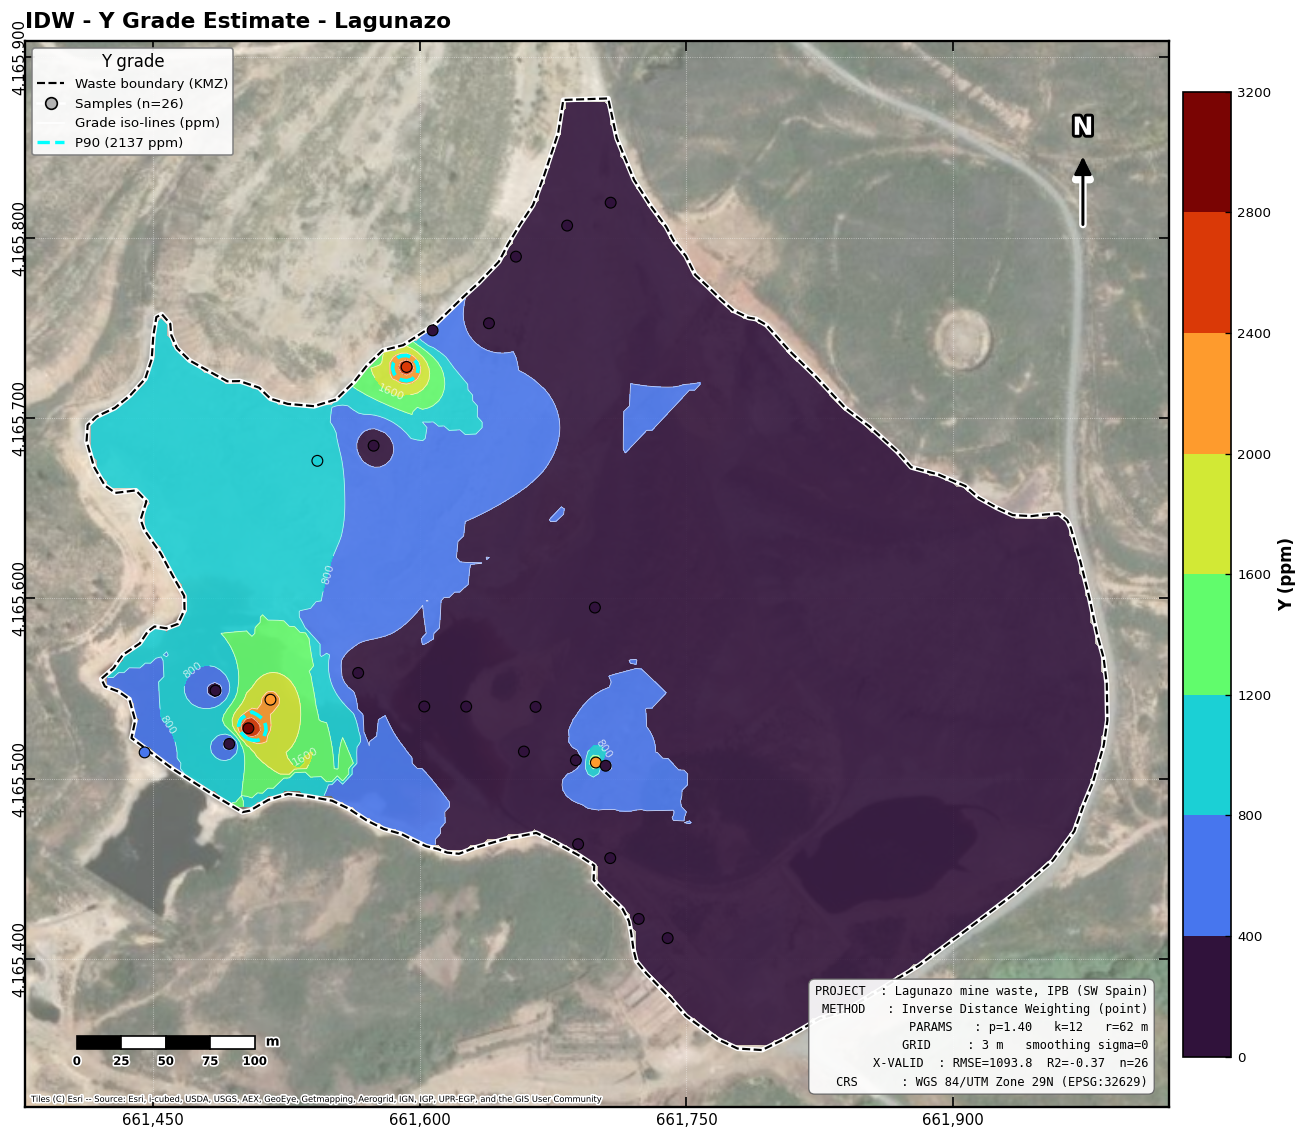

Figure 1 saved -> IDW_Y_grade_map_UTM29N.png / .pdf (400 dpi + vector)


In [194]:
fig, ax = plt.subplots(figsize=(11, 9.6))
add_satellite_basemap(ax, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, alpha=0.62, zorder=0)

# classified IDW surface
cf = ax.contourf(XG, YG, np.ma.masked_invalid(Z_disp), levels=grade_breaks,
                 cmap=grade_cmap, norm=grade_norm, alpha=0.88, zorder=2, extend="both")
cl = ax.contour(XG, YG, np.ma.masked_invalid(Z_disp), levels=grade_breaks,
                colors="white", linewidths=0.5, alpha=0.7, zorder=3)
ax.clabel(cl, levels=grade_breaks[::2], inline=True, fontsize=6.5, fmt="%.0f")
try:
    c90 = ax.contour(XG, YG, np.ma.masked_invalid(Z_disp), levels=[P90_THR],
                     colors="cyan", linewidths=2.2, linestyles="--", zorder=5)
    ax.clabel(c90, inline=True, fontsize=8, fmt="P90: %.0f")
except Exception:
    pass

# clip everything to the polygon
clip = MPath(np.column_stack([px_utm, py_utm]))
from matplotlib.patches import PathPatch
patch = PathPatch(clip, transform=ax.transData, fc="none", ec="none", zorder=4)
ax.add_patch(patch)
for coll in [cf, cl]:
    coll.set_clip_path(patch)

# samples
ax.scatter(xs_utm, ys_utm, s=42, c=vals_s, cmap=grade_cmap, norm=grade_norm,
           edgecolors="black", linewidths=0.7, zorder=11)

add_map_furniture(ax, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, px_utm, py_utm)

cb = fig.colorbar(plt.cm.ScalarMappable(norm=grade_norm, cmap=grade_cmap),
                  ax=ax, fraction=0.040, pad=0.012, boundaries=grade_breaks,
                  ticks=grade_breaks, spacing="proportional")
cb.set_label(f"{VAR_NAME} (ppm)", fontsize=10, fontweight="bold")
cb.ax.tick_params(labelsize=8)

ax.set_title(f"IDW - {VAR_NAME} Grade Estimate - Lagunazo",
             fontsize=13, fontweight="bold", loc="left", pad=8)

# GIS data-frame metadata block
info = (f"PROJECT  : Lagunazo mine waste, IPB (SW Spain)\n"
        f"METHOD   : Inverse Distance Weighting (point)\n"
        f"PARAMS   : p={BEST_P:.2f}   k={BEST_K}   r={BEST_RAD:.0f} m\n"
        f"GRID     : {GRID_DENSITY_M:g} m   smoothing sigma={SMOOTH_SIGMA:g}\n"
        f"X-VALID  : RMSE={cv_metrics['RMSE']:.1f}  R2={cv_metrics['R2_pred']:.2f}  n={cv_metrics['n']}\n"
        f"CRS      : WGS 84/UTM Zone 29N (EPSG:32629)")
ax.text(xmax_u + pad_x - 0.02*(xmax_u-xmin_u), ymin_u - pad_y + 0.02*(ymax_u-ymin_u),
        info, ha="right", va="bottom", fontsize=7.2, family="monospace", linespacing=1.5,
        zorder=20, bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="0.4", lw=0.8, alpha=0.92))

ax.legend(handles=[
    Line2D([0],[0], color="black", lw=1.3, ls="--", label=f"Waste boundary ({'KMZ' if KMZ_LOADED else 'hull'})"),
    Line2D([0],[0], marker="o", color="w", mfc="0.7", mec="black", ms=7, label=f"Samples (n={N_SAMPLES})"),
    Line2D([0],[0], color="white", lw=1.0, label="Grade iso-lines (ppm)"),
    Line2D([0],[0], color="cyan", lw=2.0, ls="--", label=f"P90 ({P90_THR:.0f} ppm)"),
], loc="upper left", fontsize=8, framealpha=0.92, edgecolor="0.5", title=f"{VAR_NAME} grade")

synth_banner(fig)
plt.tight_layout()
plt.savefig(f"IDW_{VAR_NAME}_grade_map_UTM29N.png", dpi=400, bbox_inches="tight")
plt.savefig(f"IDW_{VAR_NAME}_grade_map_UTM29N.pdf", bbox_inches="tight")
plt.show()
print(f"Figure 1 saved -> IDW_{VAR_NAME}_grade_map_UTM29N.png / .pdf (400 dpi + vector)")


## 7 · Figure 2 - Grade and Data Support


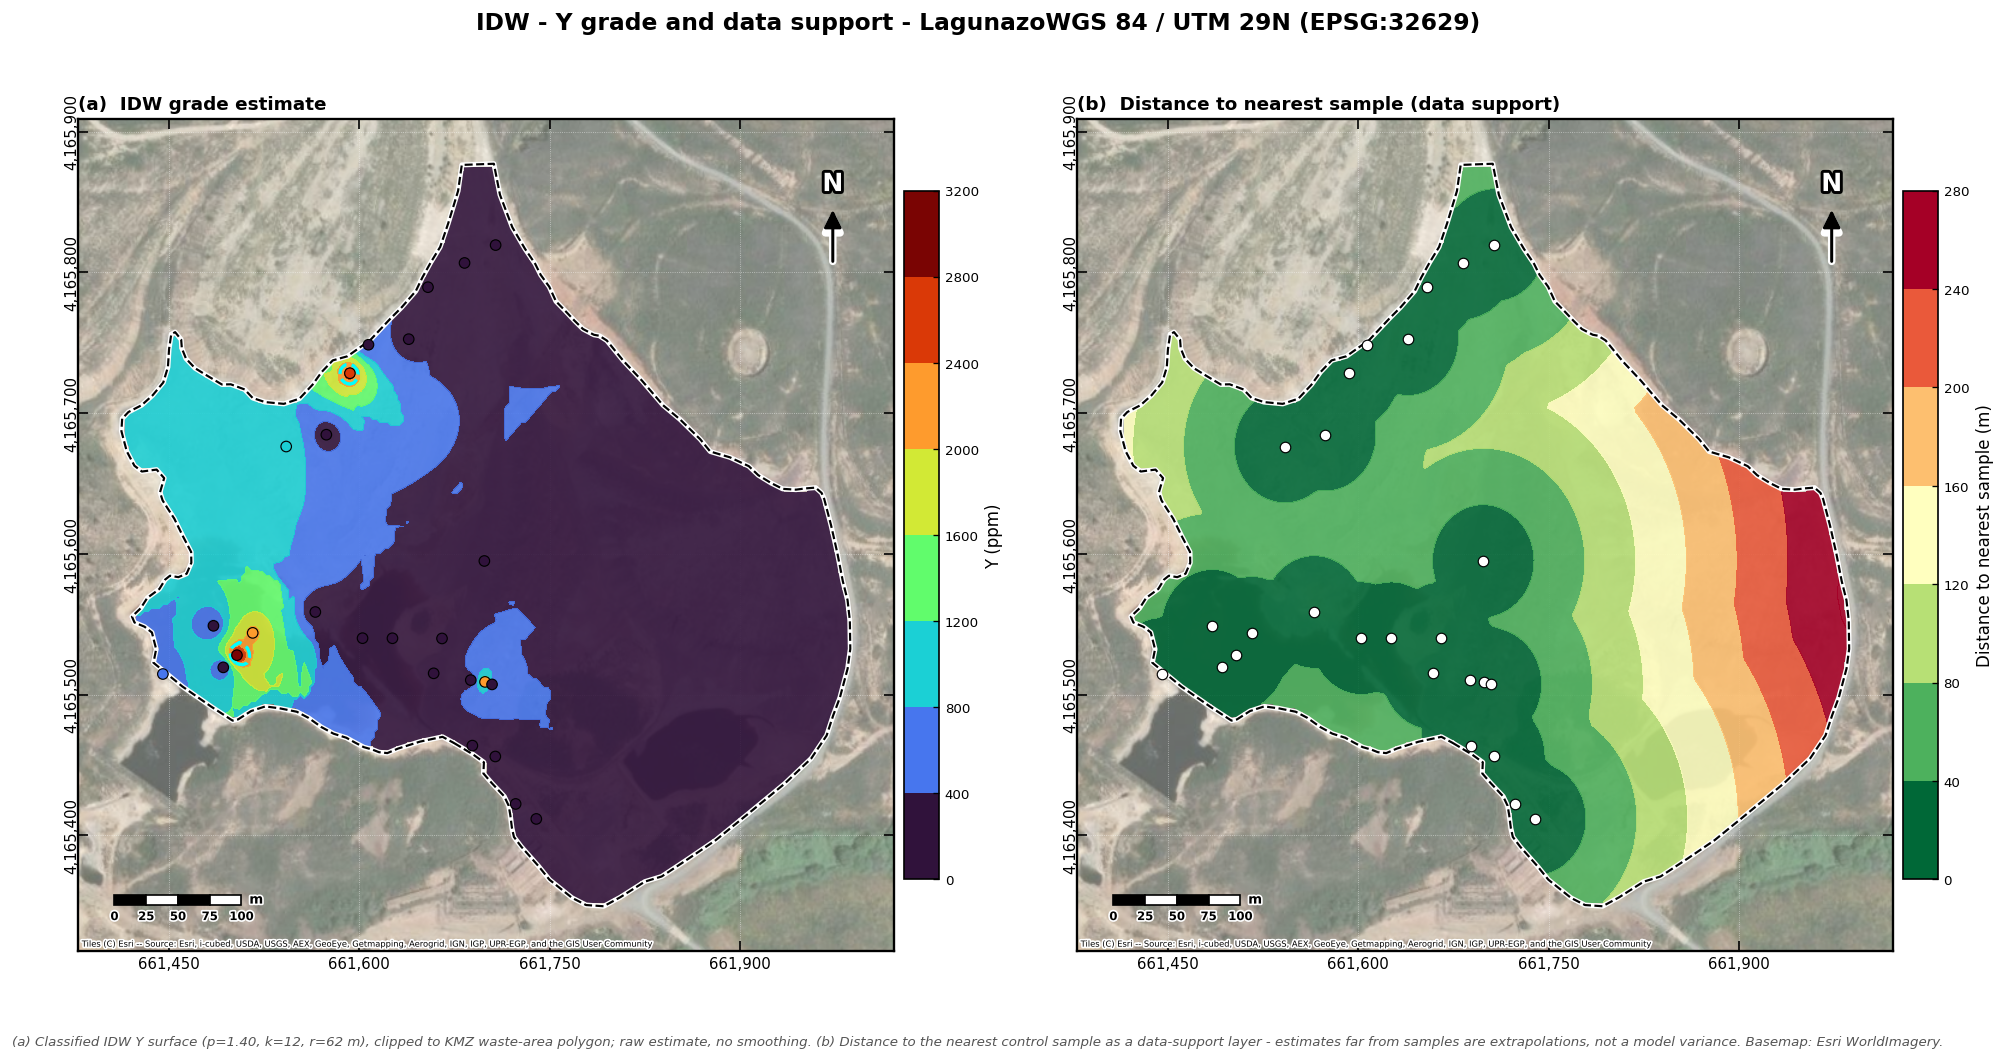

Figure 2 saved -> IDW_Y_grade_support_UTM29N.png / .pdf


In [195]:
fig, axes = plt.subplots(1, 2, figsize=(20, 9), gridspec_kw={"wspace": 0.16})
fig.suptitle(f"IDW - {VAR_NAME} grade and data support - Lagunazo"
             f"WGS 84 / UTM 29N (EPSG:32629)", fontsize=14, fontweight="bold", y=0.98)

# (a) classified grade
ax_a = axes[0]
add_satellite_basemap(ax_a, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, alpha=0.62, zorder=0)
cf_a = ax_a.contourf(XG, YG, np.ma.masked_invalid(Z_disp), levels=grade_breaks,
                     cmap=grade_cmap, norm=grade_norm, alpha=0.88, zorder=2, extend="both")
try:
    c90a = ax_a.contour(XG, YG, np.ma.masked_invalid(Z_disp), levels=[P90_THR],
                        colors="cyan", linewidths=2.0, linestyles="--", zorder=5)
except Exception:
    c90a = None
clip_a = MPath(np.column_stack([px_utm, py_utm]))
patch_a = PathPatch(clip_a, transform=ax_a.transData, fc="none", ec="none", zorder=4)
ax_a.add_patch(patch_a); cf_a.set_clip_path(patch_a)
if c90a is not None:
    c90a.set_clip_path(patch_a)
ax_a.scatter(xs_utm, ys_utm, s=40, c=vals_s, cmap=grade_cmap, norm=grade_norm,
             edgecolors="black", linewidths=0.7, zorder=11)
add_map_furniture(ax_a, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, px_utm, py_utm)
ax_a.set_title("(a)  IDW grade estimate", fontsize=11, fontweight="bold", loc="left")
cb_a = fig.colorbar(plt.cm.ScalarMappable(norm=grade_norm, cmap=grade_cmap),
                    ax=ax_a, fraction=0.040, pad=0.012, boundaries=grade_breaks,
                    ticks=grade_breaks, spacing="proportional")
cb_a.set_label(f"{VAR_NAME} (ppm)", fontsize=10); cb_a.ax.tick_params(labelsize=8)

# (b) data support = distance to nearest sample
ax_b = axes[1]
add_satellite_basemap(ax_b, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, alpha=0.62, zorder=0)
cf_b = ax_b.contourf(XG, YG, np.ma.masked_invalid(D_grid), levels=supp_breaks,
                     cmap=supp_cmap, norm=supp_norm, alpha=0.88, zorder=2, extend="max")
clip_b = MPath(np.column_stack([px_utm, py_utm]))
patch_b = PathPatch(clip_b, transform=ax_b.transData, fc="none", ec="none", zorder=4)
ax_b.add_patch(patch_b); cf_b.set_clip_path(patch_b)
ax_b.scatter(xs_utm, ys_utm, s=40, c="white", edgecolors="black", linewidths=0.7, zorder=11)
add_map_furniture(ax_b, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, px_utm, py_utm)
ax_b.set_title("(b)  Distance to nearest sample (data support)", fontsize=11, fontweight="bold", loc="left")
cb_b = fig.colorbar(plt.cm.ScalarMappable(norm=supp_norm, cmap=supp_cmap),
                    ax=ax_b, fraction=0.040, pad=0.012, boundaries=supp_breaks,
                    ticks=supp_breaks, spacing="proportional")
cb_b.set_label("Distance to nearest sample (m)", fontsize=10); cb_b.ax.tick_params(labelsize=8)

fig.text(0.5, 0.02,
    f"(a) Classified IDW {VAR_NAME} surface (p={BEST_P:.2f}, k={BEST_K}, r={BEST_RAD:.0f} m), clipped to {BND_LABEL}; "
    f"raw estimate, no smoothing. (b) Distance to the nearest control sample as a data-support layer - "
    f"estimates far from samples are extrapolations, not a model variance. Basemap: Esri WorldImagery.",
    ha="center", fontsize=8, color="#555", style="italic", va="bottom")

synth_banner(fig)
plt.savefig(f"IDW_{VAR_NAME}_grade_support_UTM29N.png", dpi=400, bbox_inches="tight")
plt.savefig(f"IDW_{VAR_NAME}_grade_support_UTM29N.pdf", bbox_inches="tight")
plt.show()
print(f"Figure 2 saved -> IDW_{VAR_NAME}_grade_support_UTM29N.png / .pdf")


## 8 · Figure 3 - Cross-Validation Performance Dashboard


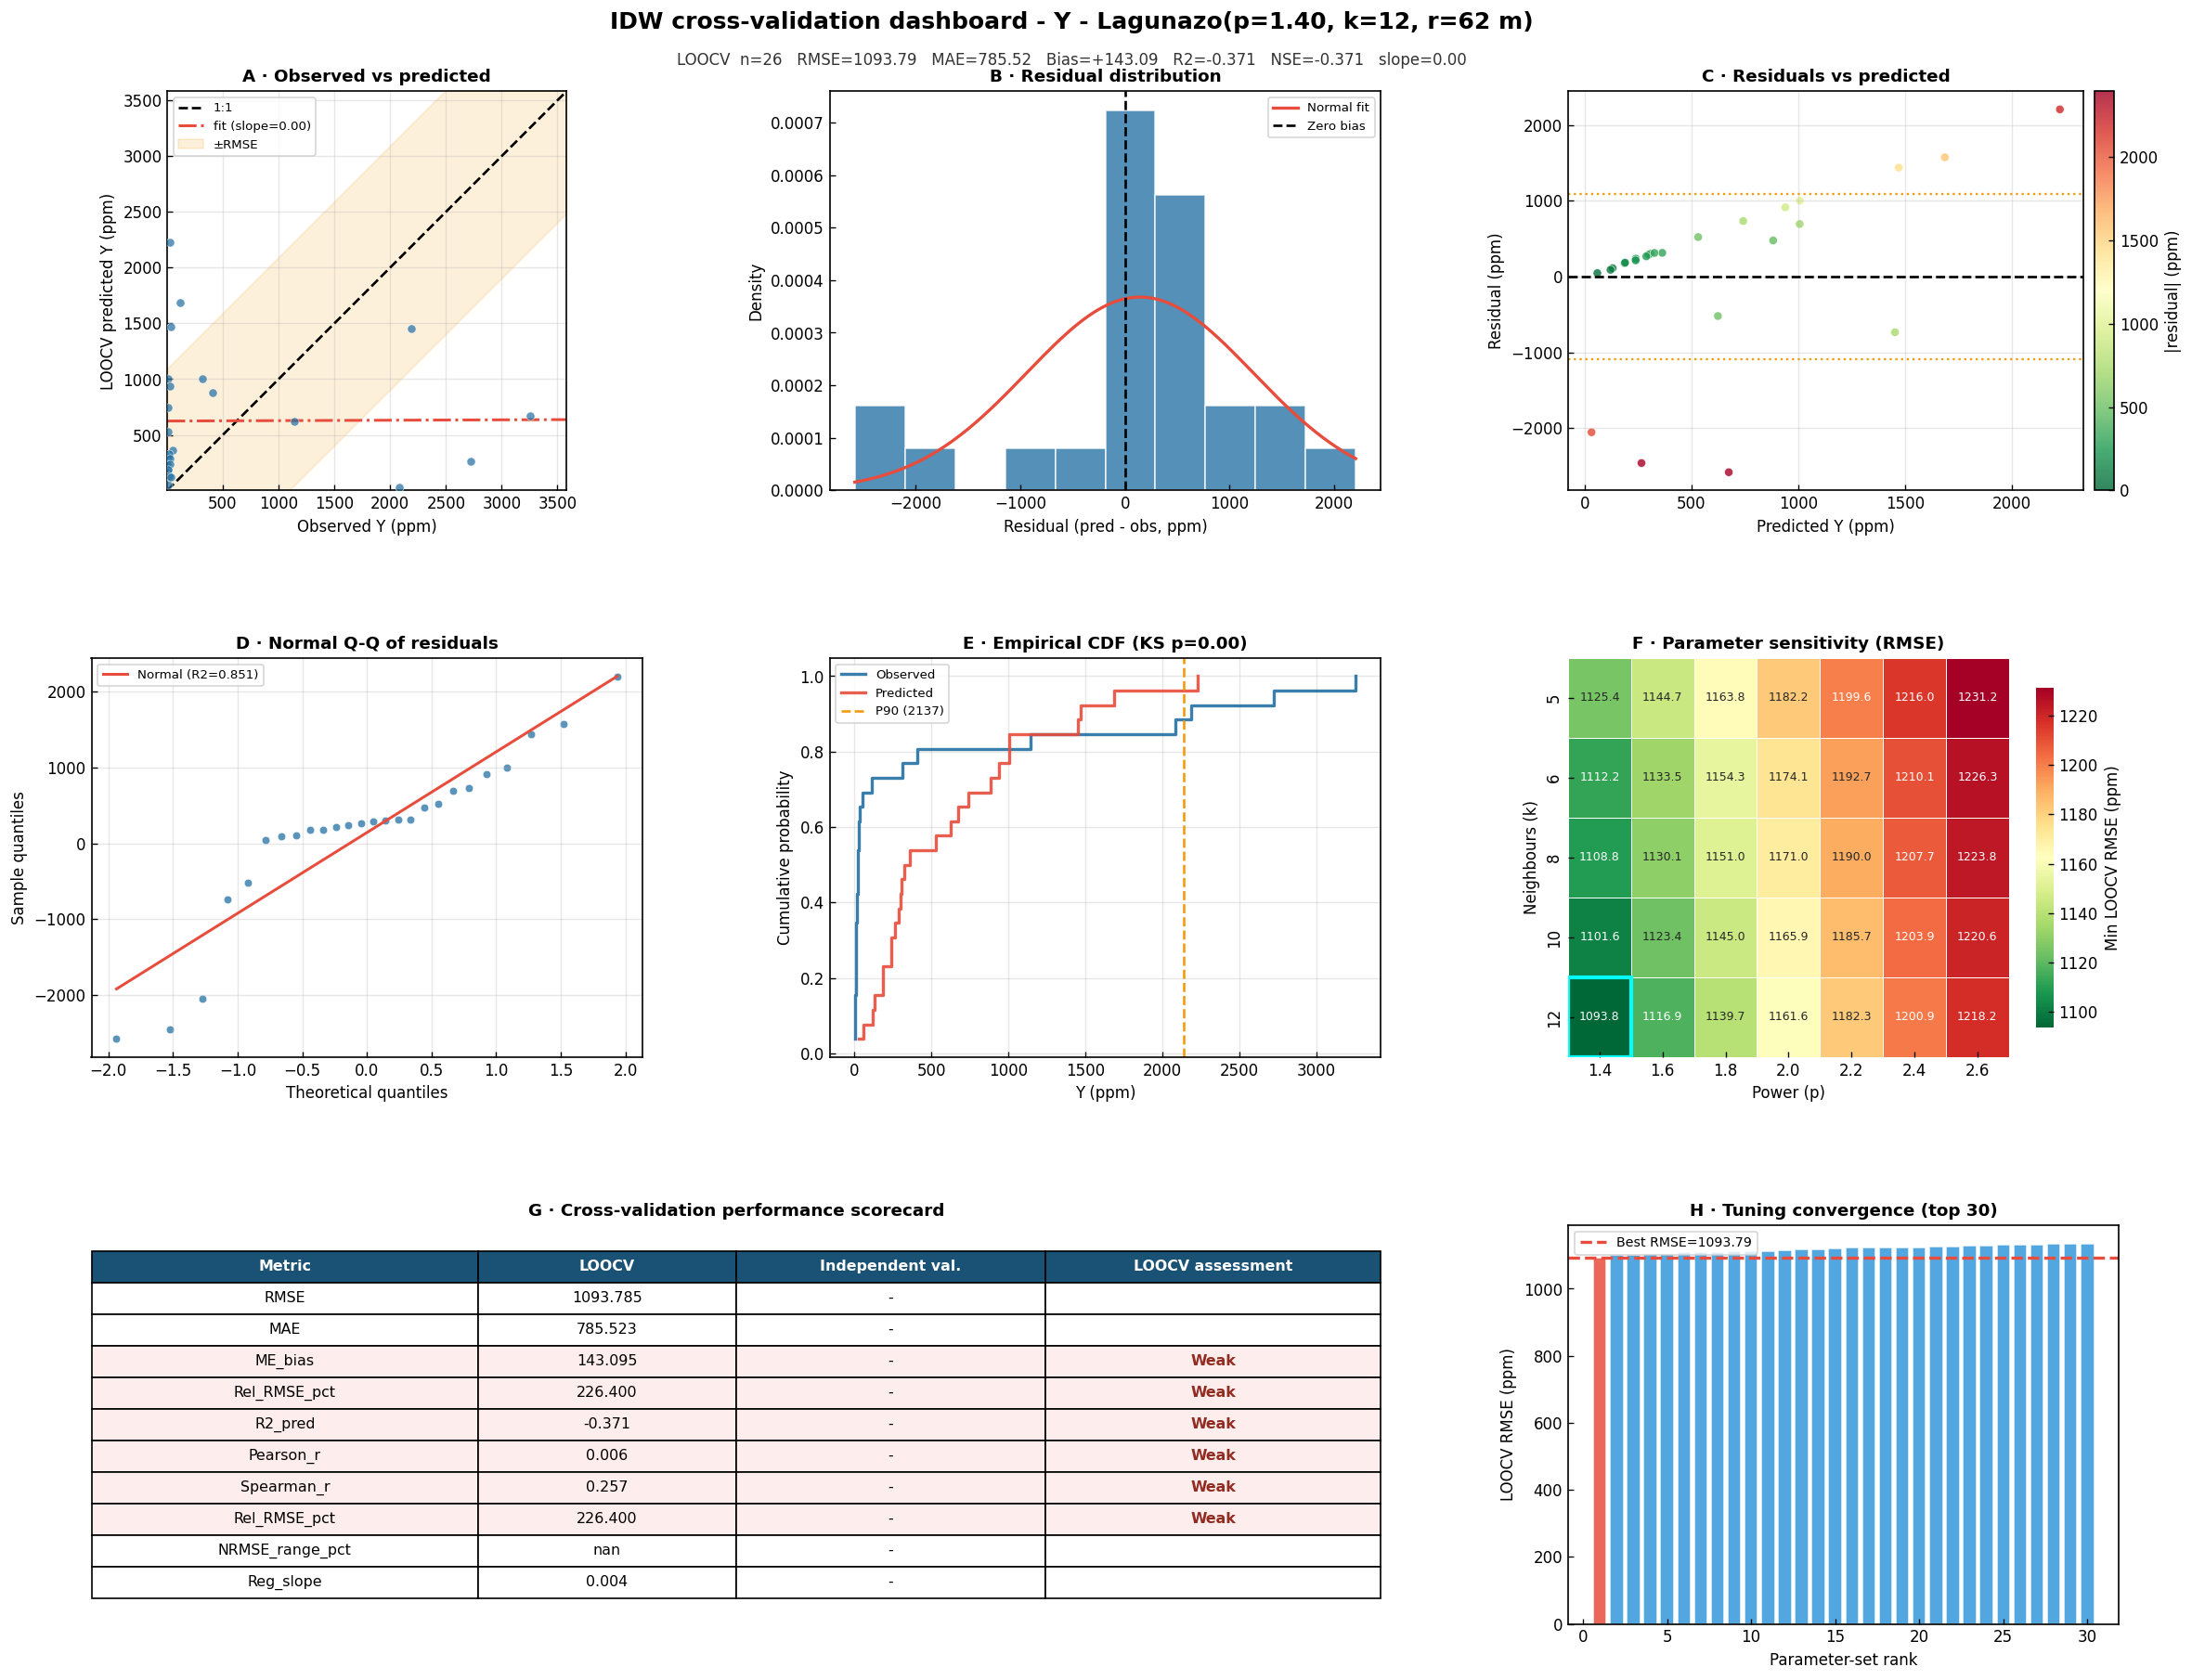

Figure 3 saved -> IDW_Y_performance_dashboard.png


In [196]:
obs  = cv_df[VAR_NAME].values
pred = cv_df["Predicted_LOOCV"].values
ok   = np.isfinite(obs) & np.isfinite(pred)
obs, pred = obs[ok], pred[ok]
resid = pred - obs
rmse_v = cv_metrics["RMSE"]; sd_r = float(resid.std())

fig = plt.figure(figsize=(20, 16))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.34,
                        left=0.06, right=0.97, top=0.92, bottom=0.06)
fig.suptitle(f"IDW cross-validation dashboard - {VAR_NAME} - Lagunazo"
             f"(p={BEST_P:.2f}, k={BEST_K}, r={BEST_RAD:.0f} m)",
             fontsize=15, fontweight="bold", y=0.965)
fig.text(0.5, 0.935,
    f"LOOCV  n={cv_metrics['n']}   RMSE={cv_metrics['RMSE']:.2f}   MAE={cv_metrics['MAE']:.2f}   "
    f"Bias={cv_metrics['ME_bias']:+.2f}   R2={cv_metrics['R2_pred']:.3f}   NSE={cv_metrics['R2_pred']:.3f}   "
    f"slope={cv_metrics['Reg_slope']:.2f}",
    ha="center", fontsize=10, color="#333")
DOT, HL = "#2471a3", "#e74c3c"

# A - Observed vs predicted
axA = fig.add_subplot(gs[0, 0])
lim = [min(obs.min(), pred.min())*0.9, max(obs.max(), pred.max())*1.1]
axA.scatter(obs, pred, s=30, alpha=0.72, color=DOT, edgecolors="white", lw=0.4, zorder=3)
axA.plot(lim, lim, "k--", lw=1.6, zorder=2, label="1:1")
if obs.size > 1 and np.nanstd(obs) > 0 and np.nanstd(pred) > 0:
    m_r, c_r = stats.linregress(obs, pred)[:2]
else:
    m_r, c_r = np.nan, np.nan
xx = np.linspace(lim[0], lim[1], 100)
if np.isfinite(m_r) and np.isfinite(c_r):
    axA.plot(xx, m_r*xx + c_r, color=HL, lw=1.8, ls="-.", label=f"fit (slope={m_r:.2f})")
axA.fill_between(lim, [v-rmse_v for v in lim], [v+rmse_v for v in lim],
                 color="#f39c12", alpha=0.15, zorder=1, label=f"±RMSE")
axA.set_xlim(lim); axA.set_ylim(lim); axA.set_aspect("equal", adjustable="box")
axA.set_xlabel(f"Observed {VAR_NAME} (ppm)"); axA.set_ylabel(f"LOOCV predicted {VAR_NAME} (ppm)")
axA.set_title("A · Observed vs predicted", fontweight="bold")
axA.legend(fontsize=8, loc="upper left"); axA.grid(alpha=0.3)

# B - Residual histogram + normal fit
axB = fig.add_subplot(gs[0, 1])
axB.hist(resid, bins=min(25, max(10, N_SAMPLES//4)), color=DOT, edgecolor="white",
         alpha=0.78, density=True)
mu_r, s_r = stats.norm.fit(resid)
xr = np.linspace(resid.min(), resid.max(), 200)
axB.plot(xr, stats.norm.pdf(xr, mu_r, s_r), color=HL, lw=2.0, label="Normal fit")
axB.axvline(0, color="black", ls="--", lw=1.6, label="Zero bias")
axB.set_xlabel("Residual (pred - obs, ppm)"); axB.set_ylabel("Density")
axB.set_title("B · Residual distribution", fontweight="bold"); axB.legend(fontsize=8)

# C - Residuals vs predicted
axC = fig.add_subplot(gs[0, 2])
scC = axC.scatter(pred, resid, s=30, c=np.abs(resid), cmap="RdYlGn_r",
                  vmin=0, vmax=np.percentile(np.abs(resid), 95),
                  alpha=0.8, edgecolors="white", lw=0.4)
axC.axhline(0, color="black", ls="--", lw=1.6)
axC.axhline(rmse_v, color="#f39c12", ls=":", lw=1.4); axC.axhline(-rmse_v, color="#f39c12", ls=":", lw=1.4)
fig.colorbar(scC, ax=axC, fraction=0.045, pad=0.02, label="|residual| (ppm)")
axC.set_xlabel(f"Predicted {VAR_NAME} (ppm)"); axC.set_ylabel("Residual (ppm)")
axC.set_title("C · Residuals vs predicted", fontweight="bold"); axC.grid(alpha=0.3)

# D - Q-Q plot
axD = fig.add_subplot(gs[1, 0])
(osm, osr), (sl, ic, rqq) = stats.probplot(resid, dist="norm")
axD.scatter(osm, osr, s=26, color=DOT, alpha=0.75, edgecolors="white", lw=0.4)
axD.plot(osm, sl*np.array(osm) + ic, color=HL, lw=1.8, label=f"Normal (R2={rqq**2:.3f})")
axD.set_xlabel("Theoretical quantiles"); axD.set_ylabel("Sample quantiles")
axD.set_title("D · Normal Q-Q of residuals", fontweight="bold"); axD.legend(fontsize=8); axD.grid(alpha=0.3)

# E - Empirical CDF
axE = fig.add_subplot(gs[1, 1])
for arr, lab, col in [(obs, "Observed", DOT), (pred, "Predicted", HL)]:
    s = np.sort(arr); p = np.arange(1, len(s)+1)/len(s)
    axE.step(s, p, where="post", color=col, lw=2.0, label=lab, alpha=0.9)
axE.axvline(P90_THR, color="#f39c12", ls="--", lw=1.6, label=f"P90 ({P90_THR:.0f})")
ks, ksp = stats.ks_2samp(obs, pred)
axE.set_xlabel(f"{VAR_NAME} (ppm)"); axE.set_ylabel("Cumulative probability")
axE.set_title(f"E · Empirical CDF (KS p={ksp:.2f})", fontweight="bold"); axE.legend(fontsize=8); axE.grid(alpha=0.3)

# F - Parameter sensitivity heatmap (RMSE over p x k)
axF = fig.add_subplot(gs[1, 2])
if len(tuning_df) >= 4:
    piv = (tuning_df.groupby(["p", "k_neighbors"])["RMSE"].min().reset_index()
                    .pivot(index="k_neighbors", columns="p", values="RMSE"))
    if SNS_OK:
        sns.heatmap(piv, annot=True, fmt=".1f", cmap="RdYlGn_r", ax=axF,
                    annot_kws={"size": 7.5}, linewidths=0.5, linecolor="white",
                    cbar_kws={"shrink": 0.85, "label": "Min LOOCV RMSE (ppm)"})
    else:
        imF = axF.imshow(piv.values, aspect="auto", cmap="RdYlGn_r")
        axF.set_xticks(range(len(piv.columns)), [f"{v:.1f}" for v in piv.columns], rotation=45)
        axF.set_yticks(range(len(piv.index)), [str(v) for v in piv.index])
        fig.colorbar(imF, ax=axF, shrink=0.85, label="Min LOOCV RMSE (ppm)")
        for yy in range(piv.shape[0]):
            for xx_ in range(piv.shape[1]):
                val = piv.values[yy, xx_]
                if np.isfinite(val):
                    axF.text(xx_, yy, f"{val:.1f}", ha="center", va="center", fontsize=7.5)
    axF.set_xlabel("Power (p)"); axF.set_ylabel("Neighbours (k)")
    axF.set_title("F · Parameter sensitivity (RMSE)", fontweight="bold")
    try:
        bp = list(piv.columns).index(min(piv.columns, key=lambda v: abs(v-BEST_P)))
        bk = list(piv.index).index(min(piv.index, key=lambda v: abs(v-BEST_K)))
        axF.add_patch(Rectangle((bp, bk), 1, 1, fill=False, edgecolor="cyan", lw=2.5, zorder=5))
    except Exception:
        pass
else:
    axF.text(0.5, 0.5, "Insufficient tuning results", ha="center", va="center", transform=axF.transAxes)
    axF.set_title("F · Parameter sensitivity", fontweight="bold")

# G - Metrics scorecard
axG = fig.add_subplot(gs[2, 0:2]); axG.axis("off")
show_keys = ["RMSE", "MAE", "ME_bias", "Rel_RMSE_pct", "R2_pred", "Pearson_r", "Spearman_r",
              "Rel_RMSE_pct", "NRMSE_range_pct", "Reg_slope"]
bands = {"ME_bias": (5, 15, "near0"), "Rel_RMSE_pct": (15, 30, "low"), "R2_pred": (0.7, 0.4, "high"),
         "Pearson_r": (0.85, 0.6, "high"), "Spearman_r": (0.85, 0.6, "high"),
         "R2_pred": (0.6, 0.3, "high"), "Rel_RMSE_pct": (25, 40, "low"),
         "NRMSE_range_pct": (12, 20, "low")}
def _assess(k, v):
    if k not in bands or not isinstance(v, (int, float)) or not np.isfinite(v):
        return ""
    a, b, kind = bands[k]
    if kind == "low":   return "Good" if v <= a else "Fair" if v <= b else "Weak"
    if kind == "high":  return "Good" if v >= a else "Fair" if v >= b else "Weak"
    if kind == "near0": return "Good" if abs(v) <= a else "Fair" if abs(v) <= b else "Weak"
    return ""
rows_g = []
for k in show_keys:
    v = cv_metrics.get(k, np.nan)
    rv = cv_metrics.get(k.replace("_pct", "") if False else k)
    val_v = val_metrics.get(k) if val_metrics else None
    rows_g.append([k,
                   f"{v:.3f}" if isinstance(v, (int, float)) else str(v),
                   (f"{val_v:.3f}" if isinstance(val_v, (int, float)) else "-") if val_metrics else "-",
                   _assess(k, v)])
cols = ["Metric", "LOOCV", "Independent val.", "LOOCV assessment"]
tbl = axG.table(cellText=rows_g, colLabels=cols, cellLoc="center", loc="center",
                colWidths=[0.30, 0.20, 0.24, 0.26])
tbl.auto_set_font_size(False); tbl.set_fontsize(9.5); tbl.scale(1.0, 1.7)
for c in range(len(cols)):
    tbl[0, c].set_facecolor("#1A5276"); tbl[0, c].set_text_props(color="white", fontweight="bold")
for r in range(1, len(rows_g)+1):
    st = rows_g[r-1][3]
    fc = "#eafaf1" if st == "Good" else "#fef9e7" if st == "Fair" else "#fdedec" if st == "Weak" else "white"
    for c in range(len(cols)):
        tbl[r, c].set_facecolor(fc)
        if c == 3 and st:
            tbl[r, c].set_text_props(fontweight="bold",
                color="#1e8449" if st == "Good" else "#b7950b" if st == "Fair" else "#922b21")
axG.set_title("G · Cross-validation performance scorecard", fontweight="bold", pad=6)

# H - Tuning convergence
axH = fig.add_subplot(gs[2, 2])
if len(tuning_df) >= 3:
    topn = min(30, len(tuning_df)); vals_h = tuning_df.head(topn)["RMSE"].values
    axH.bar(range(1, topn+1), vals_h,
            color=["#e74c3c" if i == 0 else "#3498db" for i in range(topn)],
            edgecolor="white", alpha=0.85)
    axH.axhline(cv_metrics["RMSE"], color=HL, ls="--", lw=2, label=f"Best RMSE={cv_metrics['RMSE']:.2f}")
    axH.set_xlabel("Parameter-set rank"); axH.set_ylabel("LOOCV RMSE (ppm)")
    axH.set_title("H · Tuning convergence (top 30)", fontweight="bold"); axH.legend(fontsize=8.5)
else:
    axH.text(0.5, 0.5, "Insufficient tuning results", ha="center", va="center", transform=axH.transAxes)
    axH.set_title("H · Tuning convergence", fontweight="bold")

synth_banner(fig)
plt.savefig(f"IDW_{VAR_NAME}_performance_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure 3 saved -> IDW_{VAR_NAME}_performance_dashboard.png")


## 9 · Figure 4 - Spatial Residuals and Estimation Reliability


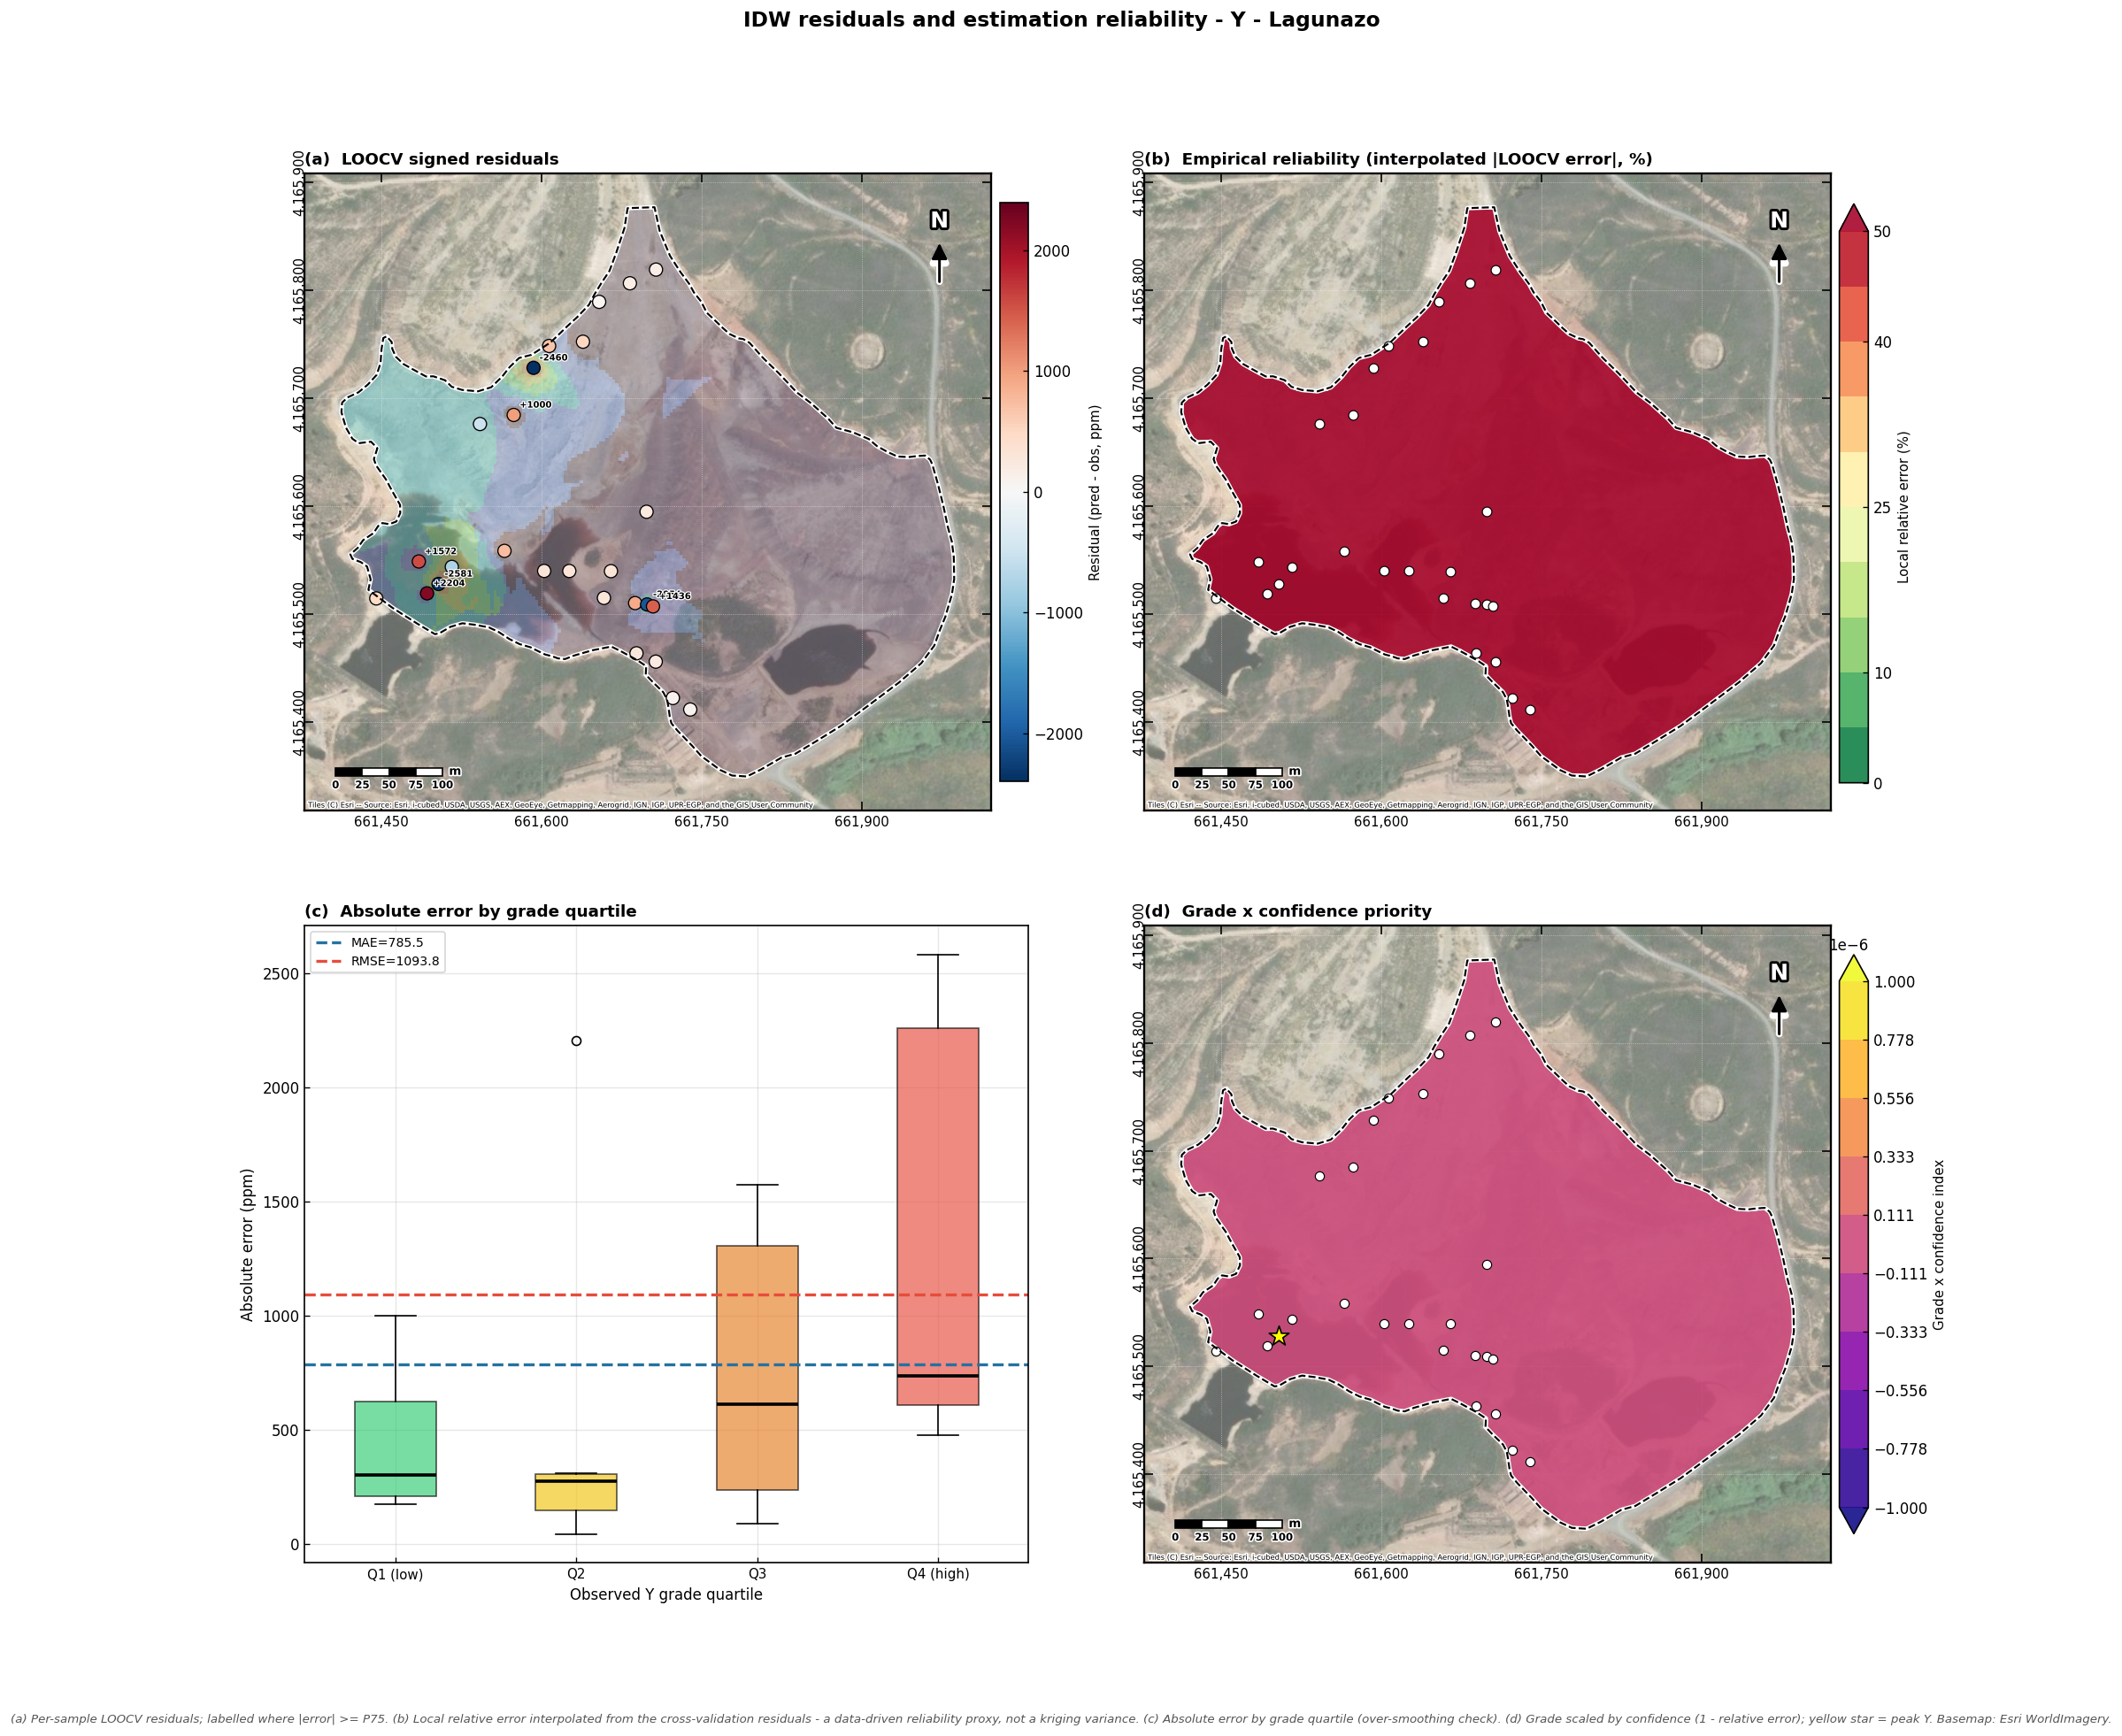

Figure 4 saved -> IDW_Y_residuals_reliability.png / .pdf


In [197]:
# Defensive import in case this cell is re-run independently after a kernel restart.
from matplotlib.patches import PathPatch

# Per-sample LOOCV residuals (already in UTM via cv_df X_utm/Y_utm)
xs_cv, ys_cv = cv_df["X_utm"].values, cv_df["Y_utm"].values
res_cv = cv_df["Residual"].values
abs_cv = cv_df["Abs_Error"].values
obs_cv = cv_df[VAR_NAME].values
rel_err_cv = np.abs(res_cv / np.where(obs_cv > 0, obs_cv, np.nan)) * 100
if np.all(~np.isfinite(rel_err_cv)):
    rel_err_cv = np.zeros_like(res_cv, dtype=float)
else:
    rel_err_cv = np.where(np.isfinite(rel_err_cv), rel_err_cv, np.nanmedian(rel_err_cv))

# Empirical reliability surface: interpolate the MAGNITUDE of LOOCV errors (metres).
tree_cv = cKDTree(np.column_stack([xs_cv, ys_cv]))
kk = min(6, len(rel_err_cv))
dC, iC = tree_cv.query(grid_pts, k=kk)
if kk == 1:
    dC = dC[:, None]; iC = iC[:, None]
epsr = 1e-9
wC = np.where(dC > epsr, 1.0 / np.maximum(dC, epsr) ** 2.0, 0.0)
wsC = wC.sum(axis=1, keepdims=True)
unc_flat = np.where(wsC.ravel() > 0, (wC * rel_err_cv[iC]).sum(axis=1) / np.maximum(wsC.ravel(), epsr), np.nan)
exC = dC[:, 0] <= epsr
unc_flat[exC] = rel_err_cv[iC[exC, 0]]
UNC_grid = np.where(in_hull, unc_flat.reshape(NROW, NCOL), np.nan)
CONF_grid = 1.0 - np.clip(UNC_grid / 50.0, 0, 1)
PRIORITY_grid = np.where(in_hull, Z_disp * CONF_grid, np.nan)

fig, axes = plt.subplots(2, 2, figsize=(19, 17), gridspec_kw={"hspace": 0.18, "wspace": 0.16})
fig.suptitle(f"IDW residuals and estimation reliability - {VAR_NAME} - Lagunazo",
             fontsize=14, fontweight="bold", y=0.97)

# (a) signed residuals at samples
axa = axes[0, 0]
add_satellite_basemap(axa, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, alpha=0.62, zorder=0)
axa.pcolormesh(XG, YG, np.ma.masked_invalid(Z_disp), cmap=grade_cmap, norm=grade_norm,
               shading="auto", alpha=0.25, zorder=1)
rmax = np.nanpercentile(np.abs(res_cv), 95)
sca = axa.scatter(xs_cv, ys_cv, s=80, c=res_cv, cmap=RESID_CMAP, vmin=-rmax, vmax=rmax,
                  edgecolors="black", linewidths=0.8, zorder=10)
thr = np.nanpercentile(abs_cv, 75)
for xi, yi, ri in zip(xs_cv, ys_cv, res_cv):
    if abs(ri) >= thr:
        axa.annotate(f"{ri:+.0f}", xy=(xi, yi), xytext=(4, 5), textcoords="offset points",
                     fontsize=6, fontweight="bold", color="black",
                     path_effects=[mpe.withStroke(linewidth=1.5, foreground="white")], zorder=12)
add_map_furniture(axa, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, px_utm, py_utm)
axa.set_title("(a)  LOOCV signed residuals", fontsize=11, fontweight="bold", loc="left")
cba = fig.colorbar(sca, ax=axa, fraction=0.040, pad=0.012); cba.set_label("Residual (pred - obs, ppm)", fontsize=9)

# (b) empirical reliability
axb = axes[0, 1]
add_satellite_basemap(axb, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, alpha=0.62, zorder=0)
mb = axb.contourf(XG, YG, np.ma.masked_invalid(UNC_grid), levels=np.linspace(0, 50, 11),
                  cmap="RdYlGn_r", vmin=0, vmax=50, alpha=0.88, zorder=2, extend="max")
clip_b2 = MPath(np.column_stack([px_utm, py_utm]))
patch_b2 = PathPatch(clip_b2, transform=axb.transData, fc="none", ec="none", zorder=4)
axb.add_patch(patch_b2); mb.set_clip_path(patch_b2)
axb.scatter(xs_cv, ys_cv, s=42, c="white", edgecolors="black", linewidths=0.7, zorder=10)
add_map_furniture(axb, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, px_utm, py_utm)
axb.set_title("(b)  Empirical reliability (interpolated |LOOCV error|, %)", fontsize=11, fontweight="bold", loc="left")
cbb = fig.colorbar(mb, ax=axb, fraction=0.040, pad=0.012, ticks=[0, 10, 25, 40, 50])
cbb.set_label("Local relative error (%)", fontsize=9)

# (c) absolute error by grade quartile
axc = axes[1, 0]
q_labels_all = ["Q1 (low)", "Q2", "Q3", "Q4 (high)"]
n_unique_grade = pd.Series(obs_cv).nunique(dropna=True)
n_q = int(min(4, max(1, n_unique_grade)))
if n_q >= 2:
    # Rank first so repeated assay values do not make qcut fail when duplicate bin edges are dropped.
    q = pd.qcut(pd.Series(obs_cv).rank(method="first"), q=n_q, labels=q_labels_all[:n_q])
    groups = [abs_cv[np.asarray(q == cat)] for cat in q.cat.categories]
    xticklabels = list(q.cat.categories)
else:
    groups = [abs_cv[np.isfinite(abs_cv)]]
    xticklabels = ["All samples"]
bp = axc.boxplot(groups, patch_artist=True, medianprops=dict(color="black", lw=2.2))
for patch, c in zip(bp["boxes"], ["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"]):
    patch.set_facecolor(c); patch.set_alpha(0.65)
axc.axhline(cv_metrics["MAE"], color="#2471a3", ls="--", lw=2, label=f"MAE={cv_metrics['MAE']:.1f}")
axc.axhline(cv_metrics["RMSE"], color="#e74c3c", ls="--", lw=2, label=f"RMSE={cv_metrics['RMSE']:.1f}")
axc.set_xticklabels(xticklabels, fontsize=9)
axc.set_xlabel(f"Observed {VAR_NAME} grade quartile"); axc.set_ylabel("Absolute error (ppm)")
axc.set_title("(c)  Absolute error by grade quartile", fontsize=11, fontweight="bold", loc="left")
axc.legend(fontsize=8.5); axc.grid(alpha=0.3)

# (d) grade x confidence priority
axd = axes[1, 1]
add_satellite_basemap(axd, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, alpha=0.62, zorder=0)
pv = PRIORITY_grid[np.isfinite(PRIORITY_grid)]
if pv.size == 0:
    pr_levels = np.linspace(0.0, 1.0, 10)
else:
    p5, p95 = float(np.nanpercentile(pv, 5)), float(np.nanpercentile(pv, 95))
    if not np.isfinite(p5) or not np.isfinite(p95) or p5 == p95:
        delta = max(abs(p5) * 0.05, 1e-6)
        p5, p95 = p5 - delta, p95 + delta
    pr_levels = np.linspace(p5, p95, 10)
md_ = axd.contourf(XG, YG, np.ma.masked_invalid(PRIORITY_grid),
                   levels=pr_levels,
                   cmap="plasma", alpha=0.88, zorder=2, extend="both")
clip_d = MPath(np.column_stack([px_utm, py_utm]))
patch_d = PathPatch(clip_d, transform=axd.transData, fc="none", ec="none", zorder=4)
axd.add_patch(patch_d); md_.set_clip_path(patch_d)
top = int(np.argmax(vals_s))
axd.scatter(xs_utm[top], ys_utm[top], s=200, marker="*", color="yellow",
            edgecolors="black", lw=1.0, zorder=12)
axd.scatter(xs_utm, ys_utm, s=38, c="white", edgecolors="black", linewidths=0.7, zorder=10)
add_map_furniture(axd, xmin_u, xmax_u, ymin_u, ymax_u, pad_x, pad_y, px_utm, py_utm)
axd.set_title("(d)  Grade x confidence priority", fontsize=11, fontweight="bold", loc="left")
cbd = fig.colorbar(md_, ax=axd, fraction=0.040, pad=0.012); cbd.set_label("Grade x confidence index", fontsize=9)

fig.text(0.5, 0.02,
    f"(a) Per-sample LOOCV residuals; labelled where |error| >= P75. "
    f"(b) Local relative error interpolated from the cross-validation residuals - a data-driven reliability proxy, "
    f"not a kriging variance. (c) Absolute error by grade quartile (over-smoothing check). "
    f"(d) Grade scaled by confidence (1 - relative error); yellow star = peak {VAR_NAME}. Basemap: Esri WorldImagery.",
    ha="center", fontsize=8, color="#555", style="italic", va="bottom")

synth_banner(fig)
plt.savefig(f"IDW_{VAR_NAME}_residuals_reliability.png", dpi=300, bbox_inches="tight")
plt.savefig(f"IDW_{VAR_NAME}_residuals_reliability.pdf", bbox_inches="tight")
plt.show()
print(f"Figure 4 saved -> IDW_{VAR_NAME}_residuals_reliability.png / .pdf")


## 10 · Export


In [198]:
# Multi-sheet Excel workbook
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

OUTPUT_XLS = f"IDW_{VAR_NAME}_Lagunazo_Analysis.xlsx"

grid_out = pd.DataFrame({
    "Easting_m":  XG.ravel(),
    "Northing_m": YG.ravel(),
    f"{VAR_NAME}_IDW_ppm":  Z_grid.ravel(),
    "Dist_NearestSample_m": D_grid.ravel(),
    "Rel_Error_pct":        UNC_grid.ravel(),
    "In_Domain":            in_hull.ravel().astype(int),
}).dropna(subset=[f"{VAR_NAME}_IDW_ppm"])

with pd.ExcelWriter(OUTPUT_XLS, engine="openpyxl") as writer:
    cv_df.round(4).to_excel(writer, sheet_name="LOOCV_Predictions", index=False)
    if val_df_out is not None:
        val_df_out.round(4).to_excel(writer, sheet_name="Independent_Validation", index=False)
    metrics_tbl.reset_index().round(4).to_excel(writer, sheet_name="Performance_Metrics", index=False)
    tuning_df.head(50).round(4).to_excel(writer, sheet_name="Tuning_Results", index=False)
    grid_out.round(4).to_excel(writer, sheet_name="Grid_Results", index=False)
    df_work.to_excel(writer, sheet_name="Input_Data", index=False)
    wb = writer.book
    for sname in ["Performance_Metrics", "Tuning_Results"]:
        ws = wb[sname]
        hdr_fill = PatternFill("solid", fgColor="1A5276"); hdr_font = Font(bold=True, color="FFFFFF", size=10)
        thin = Side(border_style="thin", color="D5D8DC"); bord = Border(thin, thin, thin, thin)
        for cell in ws[1]:
            cell.fill = hdr_fill; cell.font = hdr_font; cell.alignment = Alignment(horizontal="center")
        for row in ws.iter_rows(min_row=2):
            for cell in row:
                cell.border = bord
        for col_cells in ws.columns:
            mlen = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
            ws.column_dimensions[get_column_letter(col_cells[0].column)].width = min(mlen + 2, 26)
        ws.freeze_panes = "A2"

print(f"Excel saved -> {OUTPUT_XLS}")

# Final summary
print()
print("=" * 60)
print("  IDW INTERPOLATION COMPLETE - Lagunazo")
print("=" * 60)
print(f"  Data source     : {'SYNTHETIC (placeholder)' if SYNTHETIC else CSV_DATA}")
print(f"  Element         : {VAR_NAME}   |   n = {N_SAMPLES} samples")
print(f"  Best parameters : p={BEST_P:.2f}  k={BEST_K}  radius={BEST_RAD:.0f} m")
print(f"  LOOCV           : RMSE={cv_metrics['RMSE']:.2f}  R2={cv_metrics['R2_pred']:.3f}  "
      f"NSE={cv_metrics['R2_pred']:.3f}  bias={cv_metrics['ME_bias']:+.2f}")
if val_metrics:
    print(f"  Independent val.: RMSE={val_metrics['RMSE']:.2f}  R2={val_metrics['R2_pred']:.3f}  n={val_metrics['n']}")
print(f"  P90 anomaly     : {P90_THR:.1f} ppm")
print(f"  Grid nodes      : {int(in_hull.sum()):,} inside {BND_LABEL}")
print(f"  Rasters (.asc)  : IDW_{VAR_NAME}_grade_UTM29N.asc , IDW_{VAR_NAME}_support_dist_UTM29N.asc")
print(f"  Figures         : grade map, grade+support, dashboard, residuals/reliability (PNG + PDF)")
print(f"  Workbook        : {OUTPUT_XLS}")
print("=" * 60)


Excel saved -> IDW_Y_Lagunazo_Analysis.xlsx

  IDW INTERPOLATION COMPLETE - Lagunazo
  Data source     : Lagunazo_crm_samples_geographic5.csv
  Element         : Y   |   n = 26 samples
  Best parameters : p=1.40  k=12  radius=62 m
  LOOCV           : RMSE=1093.79  R2=-0.371  NSE=-0.371  bias=+143.09
  P90 anomaly     : 2136.8 ppm
  Grid nodes      : 18,041 inside KMZ waste-area polygon
  Rasters (.asc)  : IDW_Y_grade_UTM29N.asc , IDW_Y_support_dist_UTM29N.asc
  Figures         : grade map, grade+support, dashboard, residuals/reliability (PNG + PDF)
  Workbook        : IDW_Y_Lagunazo_Analysis.xlsx
